# 0. 분석 환경 및 공통 라이브러리

In [1]:
# ==================================================
# 0. 분석 환경 및 공통 라이브러리
# ==================================================
# 모든 코드 셀에서 사용하는 라이브러리를 첫 셀에 통합했습니다.
# 노트북을 위에서 아래 순서대로 실행하세요.

# 1. 파일 경로 및 실행 환경
from pathlib import Path                   # 원본 CSV 파일 경로 확인
import warnings                            # 시계열 모형 적합·시뮬레이션 경고 제어

# 2. 자료 처리 및 수치 계산
import numpy as np                         # 수치 계산, 예측오차 및 시뮬레이션
import pandas as pd                        # CSV 처리, 월별 시계열·비교표 생성

# 3. 표·그래프 출력
import matplotlib.pyplot as plt            # ACF/PACF 및 예측 결과 시각화
from IPython.display import display        # 노트북 내 표와 그래프 출력

# 4. 시계열 정상성 및 자기상관 분석
from statsmodels.tsa.stattools import adfuller, acf, pacf  # ADF, ACF, PACF 수치
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf  # ACF/PACF 시각화

# 5. 시계열 예측 모형
from statsmodels.tsa.statespace.sarimax import SARIMAX  # SARIMAX 적합 및 예측
from statsmodels.tsa.exponential_smoothing.ets import ETSModel  # ETS 적합 및 예측

# 6. 잔차 검정
from statsmodels.stats.diagnostic import acorr_ljungbox  # Ljung-Box 검정


# 1. 원본 데이터 불러오기

In [2]:
# ==================================================
# 1. 원본 데이터 불러오기
# ==================================================


# 1. 원본 CSV 파일 경로 설정
data_path = Path("../data") / "크루즈입항.csv"

# 2. 파일 존재 여부 확인
if not data_path.exists():
    raise FileNotFoundError(
        f"원본 CSV 파일을 찾을 수 없습니다: {data_path.resolve()}"
    )

# 3. CSV 파일 불러오기
df = pd.read_csv(data_path, encoding="euc-kr")

# 4. 데이터 확인
print("■ 데이터 불러오기 완료")
print(f"파일 경로: {data_path.resolve()}")
print(f"데이터 행 수: {len(df):,}개")
print(f"데이터 열 수: {len(df.columns)}개")

print("\n■ 컬럼 목록")
print(df.columns.tolist())

print("\n■ 원본 데이터 상위 5행")
display(df.head())

print("\n■ 원본 데이터 하위 5행")
display(df.tail())


■ 데이터 불러오기 완료
파일 경로: C:\work\cruise\data\크루즈입항.csv
데이터 행 수: 3,037개
데이터 열 수: 32개

■ 컬럼 목록
['항명', '호출부호', '선명', '입항횟수', '입항횟수.1', '구분', '외내', '입출', '총톤수', '입항일시', '출항일시', 'CIQ수속일자', '수리일시', '항해구분', 'MRN 번호', '계선장소', '계선장소.1', '계선장소.2', '차항지', '전출항지', '선박용도', '외항:한국인선원수\n내항:해기사선원수', '외항:외국인선원수\n내항:보통선원수', '승무원승선수', '승무원하선수', '승객승선수', '승객하선수', '승객', '예선', '도선', '부선호출부호1', '부선호출부호2']

■ 원본 데이터 상위 5행


,항명,호출부호,선명,입항횟수,입항횟수.1,구분,외내,입출,총톤수,입항일시,...,외항:외국인선원수\n내항:보통선원수,승무원승선수,승무원하선수,승객승선수,승객하선수,승객,예선,도선,부선호출부호1,부선호출부호2
0,부산,V7XN2,CLUB HARMONY,2013,1,최종,외항,출항,"25,558",2013-01-01 8:00,...,195,3.0,NaN,NaN,NaN,735.0,N,Y,NaN,NaN
1,부산,V7XN2,CLUB HARMONY,2013,1,최종,외항,입항,"25,558",2013-01-01 8:00,...,198,NaN,NaN,NaN,NaN,933.0,N,N,NaN,NaN
2,부산,V7XN2,CLUB HARMONY,2013,2,최종,외항,출항,"25,558",2013-01-06 7:25,...,190,6.0,NaN,NaN,NaN,197.0,N,Y,NaN,NaN
3,부산,V7XN2,CLUB HARMONY,2013,2,최종,외항,입항,"25,558",2013-01-06 7:25,...,195,NaN,NaN,NaN,NaN,754.0,N,Y,NaN,NaN
4,부산,V7XN2,CLUB HARMONY,2013,3,최종,외항,출항,"25,558",2013-01-10 5:40,...,191,5.0,NaN,NaN,NaN,481.0,N,Y,NaN,NaN



■ 원본 데이터 하위 5행


,항명,호출부호,선명,입항횟수,입항횟수.1,구분,외내,입출,총톤수,입항일시,...,외항:외국인선원수\n내항:보통선원수,승무원승선수,승무원하선수,승객승선수,승객하선수,승객,예선,도선,부선호출부호1,부선호출부호2
3032,부산,9HA6135,LUMINARA,2026,4,최종,외항,출항,"48,072",2026-10-15 6:30,...,361,6.0,4.0,1.0,14.0,224.0,Y,Y,NaN,NaN
3033,부산,ZCHI3,DIAMOND PRINCESS,2026,20,최종,외항,입항,"115,906",2026-10-16 7:00,...,1072,15.0,11.0,10.0,7.0,2724.0,Y,Y,NaN,NaN
3034,부산,ZCHI3,DIAMOND PRINCESS,2026,20,최종,외항,출항,"115,906",2026-10-16 7:00,...,1076,15.0,11.0,7.0,10.0,2721.0,Y,Y,NaN,NaN
3035,부산,7KVW,MITSUI OCEAN SAKURA,2026,3,최종,외항,출항,"34,138",2026-10-16 10:00,...,360,19.0,21.0,NaN,NaN,228.0,Y,Y,NaN,NaN
3036,부산,7KVW,MITSUI OCEAN SAKURA,2026,3,최종,외항,입항,"34,138",2026-10-16 10:00,...,362,19.0,21.0,NaN,NaN,228.0,Y,Y,NaN,NaN


# 2. 필요한 컬럼 추출 및 데이터 전처리

In [3]:
# ==================================================
# 2. 필요한 컬럼 추출 및 데이터 전처리
# ==================================================

# 1. 필요한 컬럼만 추출하여 복제본 생성
cruise = df[['호출부호', '선명', '입출', '입항일시']].copy()

# 2. 입항 데이터만 추출 (출항 데이터 제외)
cruise = cruise[cruise['입출'] == '입항'].copy()

# 3. 입항일시를 날짜 형식으로 변환
cruise['입항일시'] = pd.to_datetime(
    cruise['입항일시'],
    errors='coerce'
)

# 4. 날짜 변환에 실패한 데이터 확인
print("■ 날짜 변환 실패 건수")
print(cruise['입항일시'].isna().sum())

# 5. 입항일시가 없는 데이터 제거
cruise = cruise.dropna(subset=['입항일시'])

# 6. 분석 기간 설정 (2013년 1월 ~ 2026년 9월)
# 2026년 10월은 월 전체 실적이 없으므로 제외
cruise = cruise[
    (cruise['입항일시'] >= '2013-01-01') &
    (cruise['입항일시'] < '2026-10-01')
].copy()

# 7. 입항일시 기준 오름차순 정렬
cruise = cruise.sort_values('입항일시').reset_index(drop=True)

# 8. 전처리 결과 확인
print("\n■ 전처리 완료")
print(f"데이터 행 수: {len(cruise):,}개")
print(f"데이터 열 수: {len(cruise.columns)}개")

print("\n■ 입출 구분")
print(cruise['입출'].value_counts())

print("\n■ 분석 기간")
print("최초 입항:", cruise['입항일시'].min())
print("마지막 입항:", cruise['입항일시'].max())

print("\n■ 전처리 데이터 상위 5행")
display(cruise.head())

print("\n■ 전처리 데이터 하위 5행")
display(cruise.tail())

■ 날짜 변환 실패 건수
0

■ 전처리 완료
데이터 행 수: 1,498개
데이터 열 수: 4개

■ 입출 구분
입출
입항    1498
Name: count, dtype: int64

■ 분석 기간
최초 입항: 2013-01-01 08:00:00
마지막 입항: 2026-09-30 05:30:00

■ 전처리 데이터 상위 5행


,호출부호,선명,입출,입항일시
0,V7XN2,CLUB HARMONY,입항,2013-01-01 08:00:00
1,V7XN2,CLUB HARMONY,입항,2013-01-06 07:25:00
2,V7XN2,CLUB HARMONY,입항,2013-01-10 05:40:00
3,V7XN2,CLUB HARMONY,입항,2013-01-13 06:30:00
4,V7XN2,CLUB HARMONY,입항,2013-01-15 06:30:00



■ 전처리 데이터 하위 5행


,호출부호,선명,입출,입항일시
1493,3E7469,EASTERN VENUS,입항,2026-09-29 09:00:00
1494,C6FE7,ADORA MEDITERRANEA,입항,2026-09-29 09:00:00
1495,C6XC6,MITSUI OCEAN FUJI,입항,2026-09-29 09:00:00
1496,C6AV6,STAR NAVIGATOR,입항,2026-09-29 09:49:00
1497,C6IS6,STAR SEEKER,입항,2026-09-30 05:30:00


# 3. 월별 입항 건수 집계 및 0건 처리

In [4]:

# ==================================================
# 3. 월별 입항 건수 집계 및 0건 처리
# ==================================================

# 1. 월별 입항 건수 집계
monthly = (
    cruise.set_index('입항일시')
    .resample('MS')
    .size()
    .rename('입항건수')
)

# 2. 분석 기간의 모든 월 생성 (2013년 1월 ~ 2026년 9월)
month_index = pd.date_range(
    start='2013-01-01',
    end='2026-09-01',
    freq='MS'
)

# 3. 입항 기록이 없는 달은 0건으로 처리
# 코로나로 인한 입항 중단 기간(2020년 2월~2023년 2월)과
# 그 외 입항 스케줄이 없는 달을 모두 0건으로 처리
monthly = monthly.reindex(month_index, fill_value=0)
monthly.index.name = '연월'


# 3-1. 연도별·월별 입항 건수 비교표 및 합계

# 1. 연도별·월별 입항 건수 비교표 생성
monthly_table = monthly.to_frame()
monthly_table['연도'] = monthly_table.index.year
monthly_table['월'] = monthly_table.index.month

year_month_table = monthly_table.pivot(
    index='연도',
    columns='월',
    values='입항건수'
)

# 2. 연간 합계 추가
year_month_summary = year_month_table.copy()

year_month_summary['연간 합계'] = (
    year_month_summary.sum(axis=1)
)

# 3. 2013~2025년 합계 (모델 학습 기간)
year_month_summary.loc['2013~2025 합계'] = (
    year_month_summary.loc[2013:2025].sum(axis=0)
)

# 4. 2013~2026년 9월 합계 (검증 기간 포함)
year_month_summary.loc['2013~2026.09 합계'] = (
    year_month_summary.loc[2013:2026].sum(axis=0)
)

# 5. 연도별·월별 입항 건수 표 출력 (1개만 출력)
print("■ 연도별·월별 크루즈 입항 건수")
display(year_month_summary)


# 3-2. 데이터 집계 결과 및 코로나 기간 검증

# 1. 전체 집계 결과 확인
print("\n■ 월별 시계열 생성 완료")
print(f"전체 개월 수: {len(monthly)}개월")
print(f"월별 입항 건수 합계: {monthly.sum():,}건")
print(f"전처리된 원본 입항 기록: {len(cruise):,}건")
print(f"입항 건수가 0건인 달: {(monthly == 0).sum()}개월")

# 2. 원본 기록 건수와 월별 집계 합계 비교
assert monthly.sum() == len(cruise), \
    "월별 입항 건수 합계와 원본 입항 기록 수가 일치하지 않습니다."

# 3. 코로나로 인한 입항 중단 기간 검증 (2020년 2월 ~ 2023년 2월)
covid_months = monthly.loc['2020-02':'2023-02']

print("\n■ 코로나 입항 중단 기간 0건 처리 검증")
print(
    f"2020년 2월~2023년 2월: "
    f"{(covid_months == 0).sum()}/{len(covid_months)}개월이 0건"
)

assert len(covid_months) == 37, \
    "코로나 입항 중단 기간이 37개월과 일치하지 않습니다."

assert (covid_months == 0).all(), \
    "코로나 입항 중단 기간 중 입항 기록이 존재하는 달이 있습니다."


■ 연도별·월별 크루즈 입항 건수


월,1,2,3,4,5,6,7,8,9,10,11,12,연간 합계
연도,,,,,,,,,,,,,
2013,10.0,0.0,7.0,13.0,13.0,15.0,14.0,12.0,9.0,12.0,1.0,0.0,106.0
2014,1.0,4.0,7.0,10.0,13.0,22.0,14.0,9.0,10.0,9.0,3.0,2.0,104.0
2015,0.0,1.0,3.0,7.0,11.0,8.0,2.0,6.0,5.0,10.0,9.0,2.0,64.0
2016,7.0,5.0,7.0,12.0,25.0,17.0,23.0,32.0,30.0,23.0,15.0,9.0,205.0
2017,9.0,11.0,9.0,12.0,10.0,1.0,7.0,11.0,12.0,7.0,0.0,0.0,89.0
2018,0.0,2.0,4.0,15.0,13.0,8.0,6.0,9.0,9.0,11.0,3.0,0.0,80.0
2019,2.0,1.0,6.0,23.0,18.0,7.0,9.0,12.0,11.0,11.0,4.0,3.0,107.0
2020,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



■ 월별 시계열 생성 완료
전체 개월 수: 165개월
월별 입항 건수 합계: 1,498건
전처리된 원본 입항 기록: 1,498건
입항 건수가 0건인 달: 47개월

■ 코로나 입항 중단 기간 0건 처리 검증
2020년 2월~2023년 2월: 37/37개월이 0건


# 4. 학습·검증 데이터 분리 및 코로나 더미변수 생성

In [5]:
# ==================================================
# 4. 학습·검증 데이터 분리 및 코로나 더미변수 생성
# ==================================================

# 1. 학습 데이터 (2013년 1월 ~ 2025년 12월)
train = monthly.loc['2013-01':'2025-12'].copy()

# 2. 검증 데이터 (2026년 1월 ~ 2026년 9월)
valid = monthly.loc['2026-01':'2026-09'].copy()

# 3. 코로나 더미변수 생성 함수
# 코로나 영향 기간: 2020년 2월 ~ 2023년 2월
# 해당 기간 1, 나머지 기간 0
def make_covid_dummy(index):
    return pd.Series(
        (
            (index >= '2020-02-01') &
            (index <= '2023-02-01')
        ).astype(int),
        index=index,
        name='covid_dummy'
    )

# 4. SARIMAX에 사용할 코로나 더미변수
train_exog = make_covid_dummy(train.index)
valid_exog = make_covid_dummy(valid.index)

# 5. 데이터 분리 결과 확인
print("■ 학습·검증 데이터 분리 결과")
print(f"학습 기간: {train.index.min():%Y-%m} ~ {train.index.max():%Y-%m}")
print(f"학습 데이터: {len(train)}개월")
print(f"검증 기간: {valid.index.min():%Y-%m} ~ {valid.index.max():%Y-%m}")
print(f"검증 데이터: {len(valid)}개월")
print(f"2026년 1~9월 실제 입항수: {valid.sum():,}건")

# 6. 코로나 더미변수 확인
print("\n■ 코로나 더미변수")
print(f"학습 기간 중 코로나 더미 1: {train_exog.sum()}개월")
print(f"검증 기간 중 코로나 더미 1: {valid_exog.sum()}개월")

# 7. 데이터 개월 수 검증
assert len(train) == 156
assert len(valid) == 9
assert len(train) + len(valid) == len(monthly)

print("\n■ 데이터 분리 검증 완료")

■ 학습·검증 데이터 분리 결과
학습 기간: 2013-01 ~ 2025-12
학습 데이터: 156개월
검증 기간: 2026-01 ~ 2026-09
검증 데이터: 9개월
2026년 1~9월 실제 입항수: 319건

■ 코로나 더미변수
학습 기간 중 코로나 더미 1: 37개월
검증 기간 중 코로나 더미 1: 0개월

■ 데이터 분리 검증 완료


# 5. 시계열 정상성 검정 (ADF)

In [6]:

# ==================================================
# 5. 시계열 정상성 검정 (ADF)
# ==================================================


# 1. 차분 데이터 생성
train_diff1 = train.diff().dropna()              # 1차 차분
train_diff12 = train.diff(12).dropna()           # 12개월 계절차분
train_diff1_12 = train.diff().diff(12).dropna()  # 1차 + 계절차분


# 2. ADF 검정 함수
def adf_test(series):
    result = adfuller(series, autolag='AIC', result_object=False)

    return {
        'ADF 통계량': result[0],
        'p-value': result[1],
        '판정 (5%)': (
            '귀무가설 기각'
            if result[1] < 0.05
            else '귀무가설 기각하지 못함'
        )
    }


# 3. ADF 정상성 검정 가설
adf_hypothesis = pd.DataFrame({
    '구분': ['귀무가설(H0)', '대립가설(H1)'],
    '가설': [
        '시계열의 변화가 장기간 지속되어 안정적인 상태를 유지하지 못한다.',
        '시계열의 변화가 장기간 누적되지 않고 안정적인 상태를 유지한다.'
    ],
    '의미': [
        '비정상 시계열',
        '정상성을 뒷받침하는 근거'
    ]
})

print("■ ADF 정상성 검정 가설")
display(adf_hypothesis)


# 4. ADF 검정 판정 기준
adf_criteria = pd.DataFrame({
    '판정 기준': ['p-value < 0.05', 'p-value >= 0.05'],
    '통계적 판단': [
        '귀무가설 기각',
        '귀무가설 기각하지 못함'
    ],
    '해석': [
        '정상성을 뒷받침하는 근거가 있음',
        '정상성이 확인되지 않음'
    ]
})

print("\n■ ADF 정상성 검정 판정 기준")
display(adf_criteria)


# 5. 각 차분 단계의 ADF 검정 결과 생성
adf_table = pd.DataFrame({
    '원본 시계열': adf_test(train),
    '1차 차분 (d=1)': adf_test(train_diff1),
    '계절차분 (D=1)': adf_test(train_diff12),
    '1차+계절차분': adf_test(train_diff1_12)
}).T


# 6. ADF 검정 결과 출력
print("\n■ ADF 정상성 검정 결과")
display(adf_table.round(6))


# 7. 차분에 대한 설명
diff_info = pd.DataFrame({
    '구분': ['1차 차분', '계절차분', '1차+계절차분'],
    '쉬운 표현': [
        '전월 대비 입항건수 변화',
        '전년 같은 달 대비 입항건수 변화',
        '전월 대비 변화량의 전년 동기 비교'
    ],
    '의미': [
        '이번 달 입항건수 − 지난달 입항건수',
        '이번 달 입항건수 − 작년 같은 달 입항건수',
        '이번 달의 전월 대비 변화량 − 작년 같은 시기의 전월 대비 변화량'
    ]
})

print("\n■ 차분에 대한 설명")
display(diff_info)


■ ADF 정상성 검정 가설


,구분,가설,의미
0,귀무가설(H0),시계열의 변화가 장기간 지속되어 안정적인 상태를 유지하지 못한다.,비정상 시계열
1,대립가설(H1),시계열의 변화가 장기간 누적되지 않고 안정적인 상태를 유지한다.,정상성을 뒷받침하는 근거



■ ADF 정상성 검정 판정 기준


,판정 기준,통계적 판단,해석
0,p-value < 0.05,귀무가설 기각,정상성을 뒷받침하는 근거가 있음
1,p-value >= 0.05,귀무가설 기각하지 못함,정상성이 확인되지 않음



■ ADF 정상성 검정 결과


,ADF 통계량,p-value,판정 (5%)
원본 시계열,-2.29517,0.173531,귀무가설 기각하지 못함
1차 차분 (d=1),-3.16391,0.022171,귀무가설 기각
계절차분 (D=1),-2.907561,0.044476,귀무가설 기각
1차+계절차분,-5.492299,0.000002,귀무가설 기각



■ 차분에 대한 설명


,구분,쉬운 표현,의미
0,1차 차분,전월 대비 입항건수 변화,이번 달 입항건수 − 지난달 입항건수
1,계절차분,전년 같은 달 대비 입항건수 변화,이번 달 입항건수 − 작년 같은 달 입항건수
2,1차+계절차분,전월 대비 변화량의 전년 동기 비교,이번 달의 전월 대비 변화량 − 작년 같은 시기의 전월 대비 변화량


# 6. ACF·PACF 분석

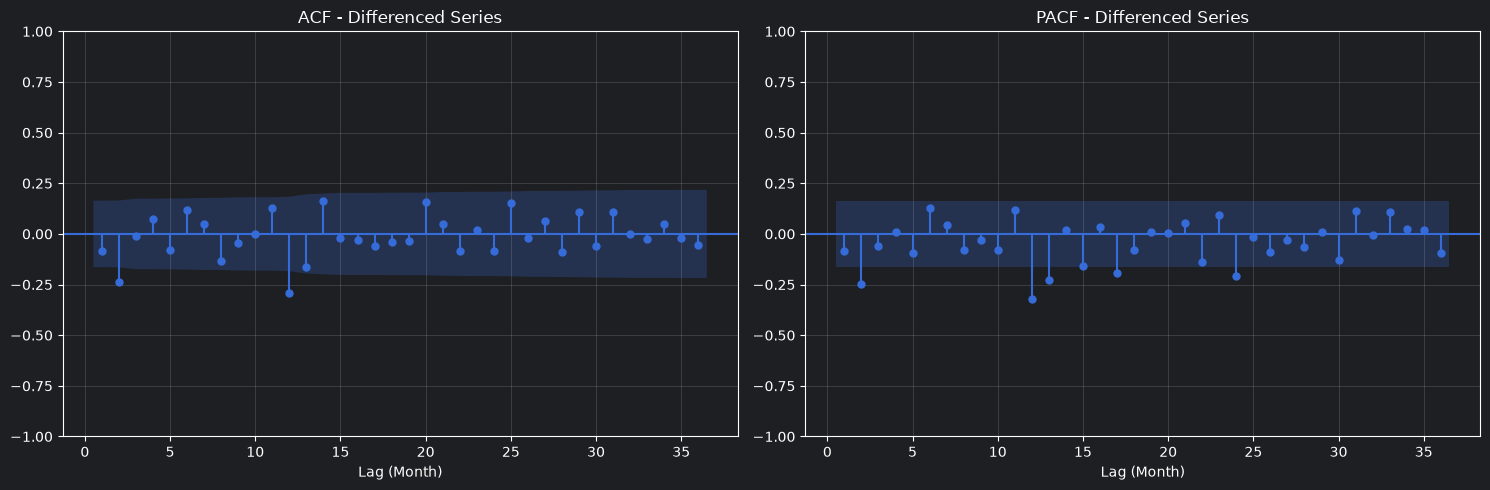

■ ACF·PACF 분석 가설


,구분,ACF,PACF
0,귀무가설(H0),해당 시차의 자기상관계수는 0이다.,해당 시차의 편자기상관계수는 0이다.
1,대립가설(H1),해당 시차의 자기상관계수는 0이 아니다.,해당 시차의 편자기상관계수는 0이 아니다.



■ ACF·PACF 분석 판정 기준 (유의수준 5%)


,판정 기준,통계적 판단,해석
0,95% 신뢰구간에 0이 포함되지 않음,귀무가설 기각,해당 시차의 상관관계가 유의함
1,95% 신뢰구간에 0이 포함됨,귀무가설 기각 못함,해당 시차의 상관관계가 유의하다고 보기 어려움


■ 주요 시차별 ACF·PACF 분석 결과


,Lag,ACF,ACF 유의성,PACF,PACF 유의성
0,1,-0.085,유의하지 않음,-0.085,유의하지 않음
1,2,-0.239,유의,-0.248,유의
2,12,-0.290,유의,-0.319,유의
3,24,-0.085,유의하지 않음,-0.209,유의
4,36,-0.056,유의하지 않음,-0.093,유의하지 않음


In [7]:
# ==================================================
# 6. ACF·PACF 분석
# ==================================================


# 1. 분석할 시차 설정 (최대 36개월)
lags = 36

# 2. ACF·PACF 값 및 95% 신뢰구간 계산
acf_values, acf_ci = acf(
    train_diff1_12,
    nlags=lags,
    alpha=0.05,
    fft=True,
    result_object=False
)

pacf_values, pacf_ci = pacf(
    train_diff1_12,
    nlags=lags,
    alpha=0.05,
    method='ywm'
)


# 3. ACF·PACF 그래프
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# ACF 그래프
plot_acf(
    train_diff1_12,
    lags=lags,
    alpha=0.05,
    zero=False,
    ax=axes[0]
)

axes[0].set_title('ACF - Differenced Series')
axes[0].set_xlabel('Lag (Month)')
axes[0].grid(alpha=0.3)

# PACF 그래프
plot_pacf(
    train_diff1_12,
    lags=lags,
    alpha=0.05,
    zero=False,
    method='ywm',
    ax=axes[1]
)

axes[1].set_title('PACF - Differenced Series')
axes[1].set_xlabel('Lag (Month)')
axes[1].grid(alpha=0.3)

plt.tight_layout()
display(fig)
plt.close(fig)


# 4. 주요 시차의 ACF·PACF 수치 정리
selected_lags = [1, 2, 12, 24, 36]

acf_pacf_rows = []

for lag in selected_lags:

    # 신뢰구간에 0이 포함되지 않으면 유의한 상관으로 표시
    acf_sig = (
        acf_ci[lag, 0] > 0 or
        acf_ci[lag, 1] < 0
    )

    pacf_sig = (
        pacf_ci[lag, 0] > 0 or
        pacf_ci[lag, 1] < 0
    )

    acf_pacf_rows.append({
        'Lag': lag,
        'ACF': acf_values[lag],
        'ACF 유의성': '유의' if acf_sig else '유의하지 않음',
        'PACF': pacf_values[lag],
        'PACF 유의성': '유의' if pacf_sig else '유의하지 않음'
    })

acf_pacf_table = pd.DataFrame(acf_pacf_rows)


# 6-1. ACF·PACF 분석 가설 및 판정 기준

# 1. ACF·PACF 분석 가설
acf_pacf_hypothesis = pd.DataFrame({
    '구분': ['귀무가설(H0)', '대립가설(H1)'],
    'ACF': [
        '해당 시차의 자기상관계수는 0이다.',
        '해당 시차의 자기상관계수는 0이 아니다.'
    ],
    'PACF': [
        '해당 시차의 편자기상관계수는 0이다.',
        '해당 시차의 편자기상관계수는 0이 아니다.'
    ]
})

print("■ ACF·PACF 분석 가설")
display(acf_pacf_hypothesis)


# 2. ACF·PACF 판정 기준
acf_pacf_criteria = pd.DataFrame({
    '판정 기준': [
        '95% 신뢰구간에 0이 포함되지 않음',
        '95% 신뢰구간에 0이 포함됨'
    ],
    '통계적 판단': [
        '귀무가설 기각',
        '귀무가설 기각 못함'
    ],
    '해석': [
        '해당 시차의 상관관계가 유의함',
        '해당 시차의 상관관계가 유의하다고 보기 어려움'
    ]
})

print("\n■ ACF·PACF 분석 판정 기준 (유의수준 5%)")
display(acf_pacf_criteria)


print("■ 주요 시차별 ACF·PACF 분석 결과")
display(acf_pacf_table.round(3))

# 7. ACF/PACF 기반 SARIMAX 후보 구성 및 최종 모형 선정

In [8]:

# ==================================================
# 7. ACF/PACF 기반 SARIMAX 후보 구성 및 최종 모형 선정
# ==================================================


# 1. ACF/PACF 분석에 따른 모수 후보 정리
# p, P는 PACF / q, Q는 ACF를 주로 참고
# 유의한 시차를 바탕으로 후보를 설정하되,
# 최종 모수는 모델 비교와 통계적 검정을 통해 선정
# d=1, D=1, s=12 고정

sar_param_candidates = pd.DataFrame({
    '모수': [
        'p (비계절 AR)',
        'q (비계절 MA)',
        'P (계절 AR)',
        'Q (계절 MA)',
        's (계절 주기)'
    ],
    '참고 근거': [
        'PACF: 2개월 시차 유의',
        'ACF: 2개월 시차 유의',
        'PACF: 12개월 및 24개월 시차 유의',
        'ACF: 12개월 시차 유의',
        '월별 자료: 12개월을 1년 주기로 설정'
    ],
    '우선 검토': [
        '2',
        '2',
        '1, 2',
        '1',
        '12'
    ],
    '탐색 후보값': [
        '0, 1, 2',
        '0, 1, 2',
        '0, 1, 2',
        '0, 1',
        '12'
    ]
})

print("■ ACF/PACF 기반 SARIMAX(p,d,q)(P,D,Q,s) 모수 후보")
display(sar_param_candidates)

print("\n■ 고정 모수")
print("일반 차분: d=1")
print("계절차분: D=1")
print("계절 주기: s=12")

print(
    "\n※ 13개월 시차는 1개월 단기 효과와 "
    "12개월 계절 효과의 결합으로 표현할 수 있음."
)


# 2. SARIMAX 후보 모형 32개 구성

# 2-1. 비계절 모수 후보 (p, d, q)
nonseasonal = [
    (0, 1, 1),
    (1, 1, 0),
    (1, 1, 1),
    (2, 1, 1),
    (1, 1, 2),
    (2, 1, 0),
    (2, 1, 2),
    (0, 1, 2)
]

# 2-2. 계절 모수 후보 (P, D, Q, s)
seasonal = [
    (0, 1, 1, 12),
    (1, 1, 0, 12),
    (1, 1, 1, 12),
    (2, 1, 1, 12)
]

# 2-3. 비계절 8개 × 계절 4개 = 32개 조합
sar_candidate_rows = []

for seasonal_order in seasonal:
    for order in nonseasonal:

        sar_candidate_rows.append({
            '번호': len(sar_candidate_rows) + 1,
            '비계절 (p,d,q)': str(order),
            '계절 (P,D,Q,s)': str(seasonal_order),
            '후보 모형': f'SARIMAX{order}×{seasonal_order}'
        })

sar_candidate_table = pd.DataFrame(sar_candidate_rows)

# 2-4. 후보 모형 개수 및 중복 검증
assert len(sar_candidate_table) == 32
assert sar_candidate_table['후보 모형'].nunique() == 32

print(f"\n■ SARIMAX 후보 모형 {len(sar_candidate_table)}개")
display(sar_candidate_table)


# 3. SARIMAX 통계적 검정 가설 및 판정 기준

# 3-1. 통계적 검정 가설
sar_hypothesis = pd.DataFrame({
    '검정': [
        'Ljung-Box 검정',
        'AR·MA 계수 유의성 검정'
    ],
    '귀무가설(H0)': [
        '잔차에 자기상관이 없다.',
        '해당 AR·MA 계수는 0이다.'
    ],
    '대립가설(H1)': [
        '잔차에 자기상관이 존재한다.',
        '해당 AR·MA 계수는 0이 아니다.'
    ]
})

print("\n■ SARIMAX 통계적 검정 가설")
display(sar_hypothesis)


# 3-2. 통계적 검정 판정 기준
sar_test_criteria = pd.DataFrame({
    '검정': [
        'Ljung-Box',
        'Ljung-Box',
        'AR·MA 계수',
        'AR·MA 계수'
    ],
    '판정 기준': [
        'p-value < 0.05',
        'p-value >= 0.05',
        'p-value < 0.05',
        'p-value >= 0.05'
    ],
    '통계적 판단': [
        '귀무가설 기각',
        '귀무가설 기각하지 못함',
        '귀무가설 기각',
        '귀무가설 기각하지 못함'
    ],
    '해석': [
        '잔차에 자기상관이 있다는 근거가 있음',
        '잔차 자기상관이 있다는 근거가 부족함',
        '해당 계수가 통계적으로 유의함',
        '해당 계수가 유의하다고 보기 어려움'
    ]
})

print("\n■ SARIMAX 통계적 검정 판정 기준")
display(sar_test_criteria)


# 3-3. 최종 모형 선정 기준
sar_selection_criteria = pd.DataFrame({
    '평가 항목': [
        '모형 수렴',
        'AR·MA 계수 유의성',
        'Ljung-Box 검정',
        'AICc'
    ],
    '선정 기준': [
        '수렴 성공 (True)',
        '모든 AR·MA 계수 p-value < 0.05',
        '12시차까지 검정한 p-value > 0.05',
        '조건 충족 후보 중 가장 낮은 값'
    ],
    '목적': [
        '모형 학습의 수렴 여부 확인',
        '모형 계수의 통계적 유의성 확인',
        '잔차의 자기상관 여부 확인',
        '적합도와 복잡도를 고려한 모형 선정'
    ]
})

print("\n■ SARIMAX 최종 모형 선정 기준")
display(sar_selection_criteria)


# 4. SARIMAX 학습 및 Ljung-Box 검정 함수

# 4-1. SARIMAX 모형 학습 함수
def fit_sarimax(data, exog, order, seasonal_order):

    model = SARIMAX(
        data,
        exog=exog,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    return model.fit(disp=False, maxiter=200)


# 4-2. Ljung-Box 잔차 검정 함수
def lb_pvalue(fitted):

    # 차분에 따른 초기 13개월 잔차 제외
    residuals = pd.Series(
        np.asarray(fitted.resid, dtype=float)
    ).iloc[13:].dropna()

    # 12시차까지 잔차의 자기상관 검정
    result = acorr_ljungbox(
        residuals,
        lags=[12],
        return_df=True
    )

    return float(result['lb_pvalue'].iloc[0])


# 5. SARIMAX 후보 모형 32개 학습 및 평가

sar_rows = []
fits_sar = {}

for seasonal_order in seasonal:
    for order in nonseasonal:

        name = f'{order}x{seasonal_order}'

        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')

                fit = fit_sarimax(
                    train,
                    train_exog,
                    order,
                    seasonal_order
                )

            # 유의하지 않은 AR·MA 계수 개수
            # 계절 AR·MA 계수도 함께 검토
            weak_terms = sum(
                (not np.isfinite(p)) or (p >= 0.05)
                for term, p in fit.pvalues.items()
                if term.startswith(('ar.', 'ma.'))
            )

            # 모형별 평가 결과 저장
            sar_rows.append({
                'model': name,
                'order': order,
                'seasonal_order': seasonal_order,
                'AICc': float(fit.aicc),
                'LB_p값': lb_pvalue(fit),
                '유의하지_않은_ARMA_계수': weak_terms,
                '수렴': bool(
                    fit.mle_retvals.get('converged', False)
                )
            })

            fits_sar[name] = fit

        except Exception as e:

            sar_rows.append({
                'model': name,
                'order': order,
                'seasonal_order': seasonal_order,
                'AICc': np.nan,
                'LB_p값': np.nan,
                '유의하지_않은_ARMA_계수': np.nan,
                '수렴': False
            })

            print(f"학습 실패: {name} / {e}")


# 6. 전체 후보 모형 평가 결과 비교

# 6-1. AICc 오름차순 정렬
sar_table = (
    pd.DataFrame(sar_rows)
    .sort_values(
        'AICc',
        ascending=True,
        na_position='last'
    )
    .reset_index(drop=True)
)

print("\n■ SARIMAX 후보 모형 비교 (AICc 오름차순)")

display(
    sar_table[[
        'model',
        'AICc',
        'LB_p값',
        '유의하지_않은_ARMA_계수',
        '수렴'
    ]].round(3)
)


# 7. 최종 선정 조건을 충족한 모형 추출

# 7-1. 모든 선정 조건을 만족하는 모형 추출
sar_valid_candidates = sar_table[
    (sar_table['수렴'] == True) &
    (sar_table['LB_p값'] > 0.05) &
    (sar_table['유의하지_않은_ARMA_계수'] == 0) &
    (sar_table['AICc'].notna())
].copy()

# 7-2. 조건 충족 후보가 없는 경우 검증 중단
if sar_valid_candidates.empty:
    raise RuntimeError(
        '모든 선정 조건을 충족한 SARIMAX 모형이 없습니다.'
    )

# 7-3. 선정 조건을 충족한 후보 출력
print(
    f"\n■ 모든 선정 조건을 충족한 후보: "
    f"{len(sar_valid_candidates)}개"
)

display(
    sar_valid_candidates[[
        'model',
        'AICc',
        'LB_p값',
        '유의하지_않은_ARMA_계수',
        '수렴'
    ]].round(3)
)


# 8. 최종 SARIMAX 모형 선정

# 8-1. 모든 조건을 충족한 후보 중 AICc가 가장 낮은 모형
sar_selected = sar_valid_candidates.iloc[0]

# 8-2. 최종 학습 모형 저장
sar_fit = fits_sar[sar_selected['model']]

# 8-3. 최종 선정 결과표
sar_final_table = pd.DataFrame([{
    '선정 모델': sar_selected['model'],
    'AICc': sar_selected['AICc'],
    'Ljung-Box p값': sar_selected['LB_p값'],
    '유의하지 않은 ARMA 계수': sar_selected[
        '유의하지_않은_ARMA_계수'
    ],
    '수렴 여부': sar_selected['수렴'],
    '선정 기준': '전체 조건 충족'
}])

print("\n■ 최종 선정 SARIMAX 모형")
display(sar_final_table.round(3))


■ ACF/PACF 기반 SARIMAX(p,d,q)(P,D,Q,s) 모수 후보


,모수,참고 근거,우선 검토,탐색 후보값
0,p (비계절 AR),PACF: 2개월 시차 유의,2,"0, 1, 2"
1,q (비계절 MA),ACF: 2개월 시차 유의,2,"0, 1, 2"
2,P (계절 AR),PACF: 12개월 및 24개월 시차 유의,"1, 2","0, 1, 2"
3,Q (계절 MA),ACF: 12개월 시차 유의,1,"0, 1"
4,s (계절 주기),월별 자료: 12개월을 1년 주기로 설정,12,12



■ 고정 모수
일반 차분: d=1
계절차분: D=1
계절 주기: s=12

※ 13개월 시차는 1개월 단기 효과와 12개월 계절 효과의 결합으로 표현할 수 있음.

■ SARIMAX 후보 모형 32개


,번호,"비계절 (p,d,q)","계절 (P,D,Q,s)",후보 모형
0,1,"(0, 1, 1)","(0, 1, 1, 12)","SARIMAX(0, 1, 1)×(0, 1, 1, 12)"
1,2,"(1, 1, 0)","(0, 1, 1, 12)","SARIMAX(1, 1, 0)×(0, 1, 1, 12)"
2,3,"(1, 1, 1)","(0, 1, 1, 12)","SARIMAX(1, 1, 1)×(0, 1, 1, 12)"
3,4,"(2, 1, 1)","(0, 1, 1, 12)","SARIMAX(2, 1, 1)×(0, 1, 1, 12)"
4,5,"(1, 1, 2)","(0, 1, 1, 12)","SARIMAX(1, 1, 2)×(0, 1, 1, 12)"
5,6,"(2, 1, 0)","(0, 1, 1, 12)","SARIMAX(2, 1, 0)×(0, 1, 1, 12)"
6,7,"(2, 1, 2)","(0, 1, 1, 12)","SARIMAX(2, 1, 2)×(0, 1, 1, 12)"
7,8,"(0, 1, 2)","(0, 1, 1, 12)","SARIMAX(0, 1, 2)×(0, 1, 1, 12)"
8,9,"(0, 1, 1)","(1, 1, 0, 12)","SARIMAX(0, 1, 1)×(1, 1, 0, 12)"
9,10,"(1, 1, 0)","(1, 1, 0, 12)","SARIMAX(1, 1, 0)×(1, 1, 0, 12)"



■ SARIMAX 통계적 검정 가설


,검정,귀무가설(H0),대립가설(H1)
0,Ljung-Box 검정,잔차에 자기상관이 없다.,잔차에 자기상관이 존재한다.
1,AR·MA 계수 유의성 검정,해당 AR·MA 계수는 0이다.,해당 AR·MA 계수는 0이 아니다.


... (6 outputs left out)


■ 모든 선정 조건을 충족한 후보: 6개


,model,AICc,LB_p값,유의하지_않은_ARMA_계수,수렴
8,"(1, 1, 2)x(0, 1, 1, 12)",773.747,0.451,0,True
9,"(0, 1, 2)x(0, 1, 1, 12)",774.134,0.462,0,True
14,"(1, 1, 1)x(0, 1, 1, 12)",779.358,0.355,0,True
24,"(1, 1, 1)x(1, 1, 0, 12)",798.251,0.320,0,True
29,"(0, 1, 2)x(1, 1, 0, 12)",806.219,0.448,0,True
31,"(0, 1, 1)x(1, 1, 0, 12)",813.162,0.056,0,True



■ 최종 선정 SARIMAX 모형


,선정 모델,AICc,Ljung-Box p값,유의하지 않은 ARMA 계수,수렴 여부,선정 기준
0,"(1, 1, 2)x(0, 1, 1, 12)",773.747,0.451,0,True,전체 조건 충족


# 8. ETS 후보 모델 비교 및 최종 선정

In [9]:
# ==================================================
# 8. ETS 후보 모델 비교 및 최종 선정
# ==================================================


# 1. ETS 모델 진단 가설
ets_hypothesis = pd.DataFrame({
    '구분': ['귀무가설(H0)', '대립가설(H1)'],
    '가설': [
        '잔차에 자기상관이 없다.',
        '잔차에 자기상관이 존재한다.'
    ]
})

print("■ ETS 모델 진단 가설 (Ljung-Box)")
display(ets_hypothesis)


# 2. ETS 모델 진단 판정 기준
ets_test_criteria = pd.DataFrame({
    '판정 기준': ['p-value < 0.05', 'p-value >= 0.05'],
    '통계적 판단': [
        '귀무가설 기각',
        '귀무가설 기각 못함'
    ],
    '해석': [
        '잔차에 자기상관이 있다는 근거가 있음',
        '잔차 자기상관이 있다는 근거가 부족함'
    ]
})

print("\n■ ETS 모델 진단 판정 기준")
display(ets_test_criteria)


# 3. ETS 최종 모델 선정 기준
ets_selection_criteria = pd.DataFrame({
    '평가 항목': ['Ljung-Box 검정', 'AICc'],
    '선정 기준': [
        'p-value > 0.05',
        '조건 충족 후보 중 가장 낮은 값'
    ],
    '목적': [
        '잔차 자기상관 점검',
        '적합도와 복잡도를 고려한 모델 선정'
    ]
})

print("\n■ ETS 최종 모델 선정 기준")
display(ets_selection_criteria)


# 4. ETS 모델 학습 함수
def fit_ets(data, spec):

    trend, damped, seasonal = spec

    model = ETSModel(
        data,
        error='add',
        trend=trend,
        damped_trend=damped,
        seasonal=seasonal,
        seasonal_periods=12 if seasonal else None
    )

    return model.fit(disp=False, maxiter=400)


# 5. ETS 후보 모델 6개 설정
ets_specs = {
    'ETS(A,N,N)': (None, False, None),
    'ETS(A,N,A)': (None, False, 'add'),
    'ETS(A,A,N)': ('add', False, None),
    'ETS(A,A,A)': ('add', False, 'add'),
    'ETS(A,Ad,N)': ('add', True, None),
    'ETS(A,Ad,A)': ('add', True, 'add')
}


# 6. ETS 후보 모델 학습
ets_rows = []
fits_ets = {}

for name, spec in ets_specs.items():

    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')

            fit = fit_ets(train, spec)

        # AICc 및 Ljung-Box 검정
        ets_rows.append({
            'model': name,
            'AICc': float(fit.aicc),
            'LB_p값': lb_pvalue(fit)
        })

        fits_ets[name] = fit

    except Exception as e:
        ets_rows.append({
            'model': name,
            'AICc': np.nan,
            'LB_p값': np.nan
        })

        print(f'학습 실패: {name} / {e}')


# 7. 후보 모델 비교표 (AICc 오름차순)
ets_table = pd.DataFrame(ets_rows)

ets_table = ets_table.sort_values(
    'AICc',
    ascending=True,
    na_position='last'
).reset_index(drop=True)

print("\n■ ETS 후보 모델 비교 (AICc 오름차순)")
display(ets_table.round(3))


# 8. Ljung-Box 검정을 통과한 모델 추출
ets_valid_candidates = ets_table[
    (ets_table['LB_p값'] > 0.05) &
    (np.isfinite(ets_table['AICc']))
]


# 9. 조건 충족 모델이 없는 경우 AICc 기준 선정
if not ets_valid_candidates.empty:
    selection_rule_ets = 'Ljung-Box 통과 후 AICc 최소'

else:
    ets_valid_candidates = ets_table[
        np.isfinite(ets_table['AICc'])
    ]

    selection_rule_ets = 'Ljung-Box 미통과, AICc 최소'

    print("\n※ Ljung-Box 검정을 통과한 ETS 후보가 없습니다.")
    print("※ AICc가 가장 낮은 모델을 잠정 선정합니다.")


if ets_valid_candidates.empty:
    raise RuntimeError(
        '정상적으로 학습된 ETS 후보 모델이 없습니다.'
    )


# 10. 최종 ETS 모델 선정
chosen_ets = ets_valid_candidates.iloc[0]

ets_fit = fits_ets[chosen_ets['model']]


# 11. 최종 선정 결과표
ets_final_table = pd.DataFrame([{
    '선정 모델': chosen_ets['model'],
    'AICc': chosen_ets['AICc'],
    'Ljung-Box p값': chosen_ets['LB_p값'],
    '잔차 검정 통과': bool(chosen_ets['LB_p값'] > 0.05),
    '선정 기준': selection_rule_ets
}])

print("\n■ 최종 선정 ETS 모델")
display(ets_final_table.round(3))

■ ETS 모델 진단 가설 (Ljung-Box)


,구분,가설
0,귀무가설(H0),잔차에 자기상관이 없다.
1,대립가설(H1),잔차에 자기상관이 존재한다.



■ ETS 모델 진단 판정 기준


,판정 기준,통계적 판단,해석
0,p-value < 0.05,귀무가설 기각,잔차에 자기상관이 있다는 근거가 있음
1,p-value >= 0.05,귀무가설 기각 못함,잔차 자기상관이 있다는 근거가 부족함



■ ETS 최종 모델 선정 기준


,평가 항목,선정 기준,목적
0,Ljung-Box 검정,p-value > 0.05,잔차 자기상관 점검
1,AICc,조건 충족 후보 중 가장 낮은 값,적합도와 복잡도를 고려한 모델 선정



■ ETS 후보 모델 비교 (AICc 오름차순)


,model,AICc,LB_p값
0,"ETS(A,N,A)",944.325,0.002
1,"ETS(A,A,A)",949.404,0.002
2,"ETS(A,Ad,A)",951.348,0.002
3,"ETS(A,N,N)",974.270,0.000
4,"ETS(A,A,N)",978.523,0.000
5,"ETS(A,Ad,N)",980.650,0.000



※ Ljung-Box 검정을 통과한 ETS 후보가 없습니다.
※ AICc가 가장 낮은 모델을 잠정 선정합니다.

■ 최종 선정 ETS 모델


,선정 모델,AICc,Ljung-Box p값,잔차 검정 통과,선정 기준
0,"ETS(A,N,A)",944.325,0.002,False,"Ljung-Box 미통과, AICc 최소"


# 9. SARIMAX·ETS 예측 성능 검증 (2026년 1~9월)

In [10]:
# ==================================================
# 9. SARIMAX·ETS 예측 성능 검증 (2026년 1~9월)
# ==================================================

# 1. 예측 성능 비교 가설
validation_hypothesis = pd.DataFrame({
    '구분': ['귀무가설(H0)', '대립가설(H1)'],
    '가설': [
        '두 모델의 월별 예측오차 수준에 차이가 없다.',
        '두 모델의 월별 예측오차 수준에 차이가 있다.'
    ]
})

print("■ 예측 성능 비교 가설")
display(validation_hypothesis)

print("※ 이번 단계는 오차 지표 비교이며, 통계적 유의성 검정은 수행하지 않습니다.")


# 2. 예측 성능 판정 기준
validation_criteria = pd.DataFrame({
    '지표': ['MAE', 'RMSE', 'RMSSE', 'MAPE', 'WAPE'],
    '의미': [
        '월평균 절대오차',
        '제곱평균제곱근오차',
        '계절 변동 크기로 보정한 RMSE',
        '월평균 절대오차율',
        '전체 실제 입항수 대비 절대오차율'
    ],
    '판정 기준': ['낮을수록 좋음'] * 5
})

print("\n■ 예측 성능 판정 기준")
display(validation_criteria)


# 3. SARIMAX 예측
# 2026년 검증 기간의 코로나 더미변수 사용
sar_pred = sar_fit.get_forecast(
    steps=len(valid),
    exog=valid_exog
).predicted_mean

sar_valid = pd.Series(
    np.maximum(np.asarray(sar_pred).reshape(-1), 0),
    index=valid.index,
    name='SARIMAX'
)


# 4. ETS 예측
ets_pred = ets_fit.forecast(steps=len(valid))

ets_valid = pd.Series(
    np.maximum(np.asarray(ets_pred).reshape(-1), 0),
    index=valid.index,
    name='ETS'
)


# 5. 예측 성능 지표 계산 함수
def calculate_metrics(actual, predicted, train_data):

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    error = actual - predicted

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))

    # RMSSE: 12개월 계절 차분을 기준으로 계산
    train_values = np.asarray(train_data, dtype=float)
    scale = np.mean(
        (train_values[12:] - train_values[:-12]) ** 2
    )

    rmsse = rmse / np.sqrt(scale) if scale > 0 else np.nan

    # MAPE: 실제값이 0인 월은 계산에서 제외
    nonzero = actual != 0
    mape = (
        np.mean(np.abs(error[nonzero] / actual[nonzero])) * 100
        if nonzero.any() else np.nan
    )

    # WAPE
    wape = (
        np.sum(np.abs(error)) / np.sum(np.abs(actual)) * 100
        if np.sum(np.abs(actual)) > 0 else np.nan
    )

    return {
        'MAE': mae,
        'RMSE': rmse,
        'RMSSE': rmsse,
        'MAPE(%)': mape,
        'WAPE(%)': wape
    }


# 6. SARIMAX·ETS 성능 비교표
validation_metrics = pd.DataFrame([
    {
        '모델': 'SARIMAX',
        **calculate_metrics(valid, sar_valid, train)
    },
    {
        '모델': 'ETS',
        **calculate_metrics(valid, ets_valid, train)
    }
])

print("\n■ 2026년 1~9월 모델별 예측 성능")
display(validation_metrics.round(2))


# 7. 월별 실제 입항수 및 예측값 비교표
validation_monthly = pd.DataFrame({
    '월': valid.index.strftime('%Y-%m'),
    '실제 입항수': valid.to_numpy().astype(int),
    'SARIMAX 예측': sar_valid.to_numpy(),
    'ETS 예측': ets_valid.to_numpy()
})

# 오차 = 실제값 - 예측값
validation_monthly['SARIMAX 오차'] = (
    validation_monthly['실제 입항수']
    - validation_monthly['SARIMAX 예측']
)

validation_monthly['ETS 오차'] = (
    validation_monthly['실제 입항수']
    - validation_monthly['ETS 예측']
)

print("\n■ 2026년 월별 실제 입항수와 예측값")
display(validation_monthly.round(2))


# 8. 검증 기간 총합 확인
print("\n■ 검증 기간 입항수 합계")
print(f"실제 입항수: {valid.sum():.0f}척")
print(f"SARIMAX 예측: {sar_valid.sum():.2f}척")
print(f"ETS 예측: {ets_valid.sum():.2f}척")

■ 예측 성능 비교 가설


,구분,가설
0,귀무가설(H0),두 모델의 월별 예측오차 수준에 차이가 없다.
1,대립가설(H1),두 모델의 월별 예측오차 수준에 차이가 있다.


※ 이번 단계는 오차 지표 비교이며, 통계적 유의성 검정은 수행하지 않습니다.

■ 예측 성능 판정 기준


,지표,의미,판정 기준
0,MAE,월평균 절대오차,낮을수록 좋음
1,RMSE,제곱평균제곱근오차,낮을수록 좋음
2,RMSSE,계절 변동 크기로 보정한 RMSE,낮을수록 좋음
3,MAPE,월평균 절대오차율,낮을수록 좋음
4,WAPE,전체 실제 입항수 대비 절대오차율,낮을수록 좋음



■ 2026년 1~9월 모델별 예측 성능


,모델,MAE,RMSE,RMSSE,MAPE(%),WAPE(%)
0,SARIMAX,18.48,20.04,2.42,50.41,52.14
1,ETS,15.07,17.42,2.10,38.42,42.52



■ 2026년 월별 실제 입항수와 예측값


,월,실제 입항수,SARIMAX 예측,ETS 예측,SARIMAX 오차,ETS 오차
0,2026-01,18,11.19,15.47,6.81,2.53
1,2026-02,20,11.16,14.89,8.84,5.11
2,2026-03,50,17.39,19.00,32.61,31.00
3,2026-04,46,26.55,25.73,19.45,20.27
4,2026-05,46,22.50,24.77,23.50,21.23
5,2026-06,41,17.23,21.34,23.77,19.66
6,2026-07,33,13.50,19.38,19.50,13.62
7,2026-08,27,15.64,21.18,11.36,5.82
8,2026-09,38,17.50,21.60,20.50,16.40



■ 검증 기간 입항수 합계
실제 입항수: 319척
SARIMAX 예측: 152.66척
ETS 예측: 183.36척


# 10. SARIMAX·ETS 미래 입항건수 예측

In [11]:

# ==================================================
# 10. SARIMAX·ETS 미래 입항건수 예측
#     - 2026년 4분기 예측
#     - 2026년 연간 입항건수 전망
#     - 2027년 두 단계·다이렉트 예측 비교
# ==================================================


# 1. 실제 관측자료 및 미래 예측 기간 설정

# 1-1. 2013년 1월~2026년 9월 실제 입항건수
observed_monthly = pd.concat([train, valid]).asfreq('MS')

assert len(observed_monthly) == 165
assert observed_monthly.index[-1] == pd.Timestamp('2026-09-01')

# 1-2. 2026년 4분기 (10~12월)
q4_2026_index = pd.date_range(
    '2026-10-01',
    periods=3,
    freq='MS'
)

# 1-3. 2027년 1~12월
year_2027_index = pd.date_range(
    '2027-01-01',
    periods=12,
    freq='MS'
)

# 1-4. 2026년 10월~2027년 12월 (총 15개월)
future_15month_index = q4_2026_index.append(year_2027_index)


# 2. 최종 선정된 SARIMAX·ETS 모형 설정

# 2-1. SARIMAX 최종 선정 모수
sarimax_order = tuple(sar_selected['order'])

sarimax_seasonal_order = tuple(
    sar_selected['seasonal_order']
)

# 2-2. ETS 최종 선정 구조
ets_selected_spec = ets_specs[chosen_ets['model']]


# 3. 미래 입항건수 예측 함수

def forecast_future(fitted, model_type, forecast_index):

    if model_type == 'SARIMAX':

        prediction = fitted.get_forecast(
            steps=len(forecast_index),
            exog=make_covid_dummy(forecast_index)
        ).predicted_mean

    elif model_type == 'ETS':

        prediction = fitted.forecast(
            steps=len(forecast_index)
        )

    else:
        raise ValueError(f'알 수 없는 모델: {model_type}')

    # 입항건수의 음수 예측값은 0으로 보정
    return pd.Series(
        np.maximum(
            np.asarray(prediction).reshape(-1),
            0
        ),
        index=forecast_index,
        name='입항건수'
    )


# 4. SARIMAX·ETS 미래 예측 수행

forecast_results = {}

for model_type in ['SARIMAX', 'ETS']:

    # 4-1. 2026년 9월까지 실제 자료로 모형 재학습
    if model_type == 'SARIMAX':

        fit_step1 = fit_sarimax(
            observed_monthly,
            make_covid_dummy(observed_monthly.index),
            sarimax_order,
            sarimax_seasonal_order
        )

    else:

        fit_step1 = fit_ets(
            observed_monthly,
            ets_selected_spec
        )

    # 4-2. 2026년 4분기 (10~12월) 예측
    forecast_2026_q4 = forecast_future(
        fit_step1,
        model_type,
        q4_2026_index
    )

    # 4-3. 다이렉트 예측
    # 2026년 9월까지의 실제 자료를 기준으로
    # 2027년 12월까지 15개월 연속 예측
    forecast_2027_direct = forecast_future(
        fit_step1,
        model_type,
        future_15month_index
    ).loc[year_2027_index]

    # 4-4. 두 단계 예측
    # 2026년 4분기 예측값을 기존 자료에 추가
    observed_plus_forecast = pd.concat([
        observed_monthly,
        forecast_2026_q4
    ]).asfreq('MS')

    # 4-5. 예측값을 추가한 자료로 2차 재학습
    if model_type == 'SARIMAX':

        fit_step2 = fit_sarimax(
            observed_plus_forecast,
            make_covid_dummy(observed_plus_forecast.index),
            sarimax_order,
            sarimax_seasonal_order
        )

    else:

        fit_step2 = fit_ets(
            observed_plus_forecast,
            ets_selected_spec
        )

    # 4-6. 두 단계 방식으로 2027년 12개월 예측
    forecast_2027_staged = forecast_future(
        fit_step2,
        model_type,
        year_2027_index
    )

    # 4-7. 모형별 예측 결과 저장
    forecast_results[model_type] = {
        'fit_step1': fit_step1,
        'fit_step2': fit_step2,
        'forecast_2026_q4': forecast_2026_q4,
        'forecast_2027_staged': forecast_2027_staged,
        'forecast_2027_direct': forecast_2027_direct
    }


# 5. 첫 번째 결과: 2026년 4분기 월별 입항건수 예측

forecast_2026_q4_table = pd.DataFrame({
    '연월': q4_2026_index.strftime('%Y-%m'),
    'SARIMAX 예측': forecast_results['SARIMAX'][
        'forecast_2026_q4'
    ].values,
    'ETS 예측': forecast_results['ETS'][
        'forecast_2026_q4'
    ].values
})

# 4분기 합계 추가
forecast_2026_q4_table.loc[len(forecast_2026_q4_table)] = {
    '연월': '4분기 합계',
    'SARIMAX 예측': forecast_results['SARIMAX'][
        'forecast_2026_q4'
    ].sum(),
    'ETS 예측': forecast_results['ETS'][
        'forecast_2026_q4'
    ].sum()
}

print("\n■ 2026년 4분기 월별 입항건수 예측")
display(forecast_2026_q4_table.round(2))


# 6. 두 번째 결과: 2026년 연간 입항건수 전망

# 2026년 1~9월 실제 입항건수
# + 2026년 10~12월 예측 입항건수

forecast_2026_annual_table = pd.DataFrame([
    {
        '모델': model_type,
        '1~9월 실제 입항건수': valid.sum(),
        '4분기 예측 입항건수': forecast_results[
            model_type
        ]['forecast_2026_q4'].sum(),
        '2026년 연간 전망': (
            valid.sum()
            + forecast_results[model_type][
                'forecast_2026_q4'
            ].sum()
        )
    }
    for model_type in ['SARIMAX', 'ETS']
])

print("\n■ 2026년 연간 입항건수 전망")
display(forecast_2026_annual_table.round(2))


# 7. 세 번째 결과: 2027년 예측 방식 설명

forecast_method_info = pd.DataFrame({
    '구분': [
        '다이렉트 예측',
        '두 단계 예측'
    ],
    '예측 방식': [
        '2026년 9월까지의 실제 자료로 15개월 연속 예측',
        '2026년 4분기를 먼저 예측한 후 2027년 재예측'
    ],
    '2027년 예측 과정': [
        '15개월 예측 중 2027년 1~12월 결과 사용',
        '4분기 예측값을 학습자료에 추가하고 모형을 재학습'
    ],
    '특징': [
        '추가 재학습 없이 미래를 연속적으로 전망',
        '예측값을 추가한 재학습 결과를 반영'
    ]
})

print("\n■ 2027년 두 단계·다이렉트 예측 방식 설명")
display(forecast_method_info)

print(
    "\n※ 두 단계 예측의 2026년 4분기 자료는 "
    "실제 관측값이 아닌 모델 예측값입니다."
)


# 8. 네 번째 결과: 2027년 월별 예측 방식 비교

forecast_2027_monthly_table = pd.DataFrame({
    '연월': year_2027_index.strftime('%Y-%m')
})

for model_type in ['SARIMAX', 'ETS']:

    # 두 단계 예측 결과
    staged = forecast_results[model_type][
        'forecast_2027_staged'
    ]

    # 다이렉트 예측 결과
    direct = forecast_results[model_type][
        'forecast_2027_direct'
    ]

    # 월별 예측값 및 차이 계산
    forecast_2027_monthly_table[
        f'{model_type} 두 단계'
    ] = staged.values

    forecast_2027_monthly_table[
        f'{model_type} 다이렉트'
    ] = direct.values

    forecast_2027_monthly_table[
        f'{model_type} 차이'
    ] = staged.values - direct.values


print("\n■ 2027년 월별 두 단계·다이렉트 예측 비교")
display(forecast_2027_monthly_table.round(3))

print(
    "※ 차이 = 두 단계 예측값 - 다이렉트 예측값"
)


# 9. 다섯 번째 결과: 2027년 연간 전망 차이

forecast_2027_summary_rows = []

for model_type in ['SARIMAX', 'ETS']:

    staged = forecast_results[model_type][
        'forecast_2027_staged'
    ]

    direct = forecast_results[model_type][
        'forecast_2027_direct'
    ]

    # 월별 예측값 차이
    difference = staged.values - direct.values

    forecast_2027_summary_rows.append({
        '모델': model_type,
        '두 단계 연간 전망': staged.sum(),
        '다이렉트 연간 전망': direct.sum(),
        '연간 합계 차이': staged.sum() - direct.sum(),
        '월평균 절대차이': np.mean(np.abs(difference)),
        '월최대 절대차이': np.max(np.abs(difference))
    })

forecast_2027_summary_table = pd.DataFrame(
    forecast_2027_summary_rows
)

print("\n■ 2027년 예측 방식별 연간 전망 및 차이")
display(forecast_2027_summary_table.round(3))


# 10. 여섯 번째 결과: 미래 예측 완료

print("\n■ 미래 예측 완료")
print(f"실제 관측자료: {len(observed_monthly)}개월")
print(f"2026년 4분기 예측: {len(q4_2026_index)}개월")
print(f"2027년 예측: {len(year_2027_index)}개월")
print(f"예측 모델: {list(forecast_results.keys())}")



■ 2026년 4분기 월별 입항건수 예측


,연월,SARIMAX 예측,ETS 예측
0,2026-10,39.97,36.97
1,2026-11,36.85,32.06
2,2026-12,34.62,30.00
3,4분기 합계,111.44,99.04



■ 2026년 연간 입항건수 전망


,모델,1~9월 실제 입항건수,4분기 예측 입항건수,2026년 연간 전망
0,SARIMAX,319,111.44,430.44
1,ETS,319,99.04,418.04



■ 2027년 두 단계·다이렉트 예측 방식 설명


,구분,예측 방식,2027년 예측 과정,특징
0,다이렉트 예측,2026년 9월까지의 실제 자료로 15개월 연속 예측,15개월 예측 중 2027년 1~12월 결과 사용,추가 재학습 없이 미래를 연속적으로 전망
1,두 단계 예측,2026년 4분기를 먼저 예측한 후 2027년 재예측,4분기 예측값을 학습자료에 추가하고 모형을 재학습,예측값을 추가한 재학습 결과를 반영



※ 두 단계 예측의 2026년 4분기 자료는 실제 관측값이 아닌 모델 예측값입니다.

■ 2027년 월별 두 단계·다이렉트 예측 비교


,연월,SARIMAX 두 단계,SARIMAX 다이렉트,SARIMAX 차이,ETS 두 단계,ETS 다이렉트,ETS 차이
0,2027-01,34.681,34.686,-0.006,30.142,30.140,0.002
1,2027-02,34.868,34.874,-0.006,29.656,29.655,0.000
2,2027-03,50.927,50.975,-0.048,35.526,35.525,0.002
3,2027-04,56.517,56.557,-0.040,41.396,41.397,-0.001
4,2027-05,53.036,53.076,-0.040,40.409,40.410,-0.000
5,2027-06,46.964,46.996,-0.032,36.780,36.778,0.001
6,2027-07,41.088,41.110,-0.022,34.292,34.290,0.002
7,2027-08,40.504,40.517,-0.013,35.448,35.447,0.001
8,2027-09,46.049,46.077,-0.028,36.533,36.531,0.002
9,2027-10,48.133,48.162,-0.030,36.972,36.973,-0.000


※ 차이 = 두 단계 예측값 - 다이렉트 예측값

■ 2027년 예측 방식별 연간 전망 및 차이


,모델,두 단계 연간 전망,다이렉트 연간 전망,연간 합계 차이,월평균 절대차이,월최대 절대차이
0,SARIMAX,541.982,542.313,-0.331,0.028,0.048
1,ETS,419.220,419.211,0.008,0.001,0.002



■ 미래 예측 완료
실제 관측자료: 165개월
2026년 4분기 예측: 3개월
2027년 예측: 12개월
예측 모델: ['SARIMAX', 'ETS']


# 11. 2027년 연간 입항수 95% 근사 예측구간

■ 예측구간 분석 가정


,구분,내용
0,기본 가정,과거 모형과 오차의 특성이 미래에도 대체로 유지된다.
1,두 단계 예측,4분기 예측값으로 재학습한 모형에 4분기 불확실성을 근사적으로 추가한다.
2,다이렉트 예측,2026년 10월부터 2027년 12월까지 연속된 미래 경로를 생성한다.
3,해석상 한계,근사 예측구간이며 실제 입항수의 포함을 보장하지 않는다.



■ 예측구간 산출 및 해석 기준


,항목,기준
0,시뮬레이션 횟수,"모델별·방식별 1,000개 미래 경로"
1,두 단계 예측,4분기 불확실성의 영향을 민감도 방식으로 근사
2,다이렉트 예측,15개월 연속 시뮬레이션 후 2027년 12개월 추출
3,95% 예측구간 하한,연간 시뮬레이션 합계의 2.5% 분위수
4,95% 예측구간 상한,연간 시뮬레이션 합계의 97.5% 분위수
5,연간 합계 계산,각 시뮬레이션의 12개월을 먼저 합산
6,입항수 범위,음수로 생성된 입항수는 0으로 보정



■ SARIMAX 시뮬레이션: 두 단계·다이렉트 각각 1,000회

■ ETS 시뮬레이션: 두 단계·다이렉트 각각 1,000회

■ 2027년 연간 입항수 95% 근사 예측구간


,모델,예측 방식,2027년 연간 점예측,95% 예측구간 하한,95% 예측구간 상한
0,SARIMAX,두 단계,541.98,351.69,746.06
1,SARIMAX,다이렉트,542.31,362.19,734.19
2,ETS,두 단계,419.22,196.90,713.63
3,ETS,다이렉트,419.21,197.03,700.23


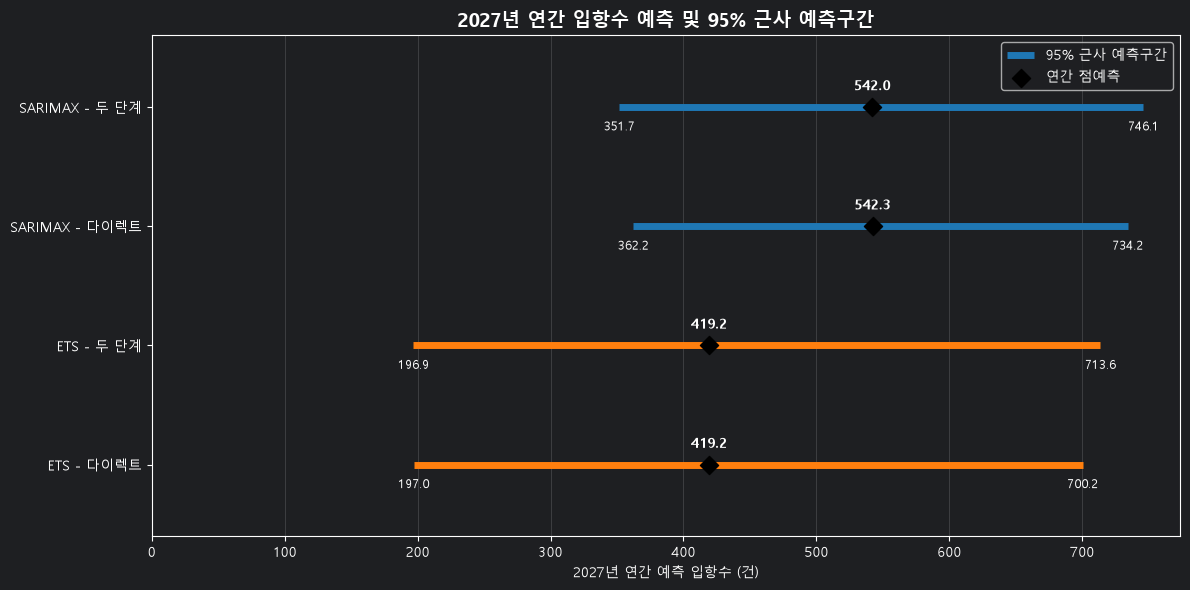


■ 예측구간 시뮬레이션 완료
시뮬레이션 횟수: 방식별 1,000회
분석 대상: 2027년 1~12월
예측 모델: SARIMAX, ETS
예측 방식: 두 단계, 다이렉트
예측구간 수준: 95% (근사)
결과: 총 4개 예측구간


In [12]:

# ==================================================
# 11. 2027년 연간 입항수 95% 근사 예측구간
#     - 몬테카를로 시뮬레이션 1,000회
#     - SARIMAX·ETS 각각 두 단계 및 다이렉트 예측
#     - 2026년 4분기 예측 불확실성 반영
#     - 2027년 연간 예측구간 비교 및 시각화
# ==================================================


# 한글 폰트 설정 (Windows)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False


# 1. 예측구간 분석 가정

forecast_interval_hypothesis = pd.DataFrame({
    '구분': [
        '기본 가정',
        '두 단계 예측',
        '다이렉트 예측',
        '해석상 한계'
    ],
    '내용': [
        '과거 모형과 오차의 특성이 미래에도 대체로 유지된다.',
        '4분기 예측값으로 재학습한 모형에 4분기 불확실성을 근사적으로 추가한다.',
        '2026년 10월부터 2027년 12월까지 연속된 미래 경로를 생성한다.',
        '근사 예측구간이며 실제 입항수의 포함을 보장하지 않는다.'
    ]
})

print("■ 예측구간 분석 가정")
display(forecast_interval_hypothesis)


# 2. 예측구간 산출 및 해석 기준

forecast_interval_criteria = pd.DataFrame({
    '항목': [
        '시뮬레이션 횟수',
        '두 단계 예측',
        '다이렉트 예측',
        '95% 예측구간 하한',
        '95% 예측구간 상한',
        '연간 합계 계산',
        '입항수 범위'
    ],
    '기준': [
        '모델별·방식별 1,000개 미래 경로',
        '4분기 불확실성의 영향을 민감도 방식으로 근사',
        '15개월 연속 시뮬레이션 후 2027년 12개월 추출',
        '연간 시뮬레이션 합계의 2.5% 분위수',
        '연간 시뮬레이션 합계의 97.5% 분위수',
        '각 시뮬레이션의 12개월을 먼저 합산',
        '음수로 생성된 입항수는 0으로 보정'
    ]
})

print("\n■ 예측구간 산출 및 해석 기준")
display(forecast_interval_criteria)


# 3. 시뮬레이션 설정

simulation_count = 1000
simulation_seed = 20261029

# 2026년 10월 ~ 2027년 12월: 총 15개월
direct_simulation_index = q4_2026_index.append(
    year_2027_index
)

assert len(q4_2026_index) == 3
assert len(year_2027_index) == 12
assert len(direct_simulation_index) == 15


# 4. SARIMAX 미래 경로 시뮬레이션 함수

def simulate_sarimax_paths(fitted, forecast_index, seed):

    steps = len(forecast_index)

    simulated = fitted.simulate(
        nsimulations=steps,
        anchor='end',
        repetitions=simulation_count,
        exog=make_covid_dummy(forecast_index),
        rng=np.random.default_rng(seed)
    )

    paths = np.asarray(simulated, dtype=float).reshape(
        steps, simulation_count
    )

    if not np.isfinite(paths).all():
        raise ValueError(
            'SARIMAX 시뮬레이션에 비정상 값이 있습니다.'
        )

    return paths


# 5. ETS 미래 경로 시뮬레이션 함수

def simulate_ets_paths(fitted, forecast_index, seed):

    steps = len(forecast_index)

    # 기존 모형의 잔차를 복원추출
    residuals = np.asarray(fitted.resid, dtype=float)
    residuals = residuals[np.isfinite(residuals)]

    if len(residuals) == 0:
        raise ValueError(
            'ETS 잔차를 확인할 수 없습니다.'
        )

    random_errors = np.random.default_rng(seed).choice(
        residuals,
        size=(steps, simulation_count),
        replace=True
    )

    simulated = fitted.simulate(
        nsimulations=steps,
        anchor='end',
        repetitions=simulation_count,
        random_errors=random_errors
    )

    paths = np.asarray(simulated, dtype=float).reshape(
        steps, simulation_count
    )

    if not np.isfinite(paths).all():
        raise ValueError(
            'ETS 시뮬레이션에 비정상 값이 있습니다.'
        )

    return paths


# 6. SARIMAX·ETS 예측구간 시뮬레이션

# 기존 변수: 두 단계 예측 결과
forecast_interval_results = {}

# 신규 변수: 다이렉트 예측 결과
forecast_interval_direct_results = {}

for model_type in ['SARIMAX', 'ETS']:

    print(
        f"\n■ {model_type} 시뮬레이션: "
        f"두 단계·다이렉트 각각 {simulation_count:,}회"
    )

    # 10번에서 생성한 재학습 모델 사용
    fit_step1 = forecast_results[model_type]['fit_step1']
    fit_step2 = forecast_results[model_type]['fit_step2']

    # --------------------------------------------------
    # 6-1. 다이렉트 방식: 15개월 연속 시뮬레이션
    # --------------------------------------------------

    if model_type == 'SARIMAX':

        direct_all_paths = simulate_sarimax_paths(
            fit_step1,
            direct_simulation_index,
            simulation_seed
        )

    else:

        direct_all_paths = simulate_ets_paths(
            fit_step1,
            direct_simulation_index,
            simulation_seed
        )

    # 15개월 중 2026년 4분기 3개월
    q4_paths = np.maximum(
        direct_all_paths[:3, :],
        0
    )

    # 15개월 중 2027년 12개월
    direct_2027_paths = np.maximum(
        direct_all_paths[3:, :],
        0
    )

    # --------------------------------------------------
    # 6-2. 다이렉트 방식: 2027년 예측구간 계산
    # --------------------------------------------------

    direct_monthly_lower = np.quantile(
        direct_2027_paths,
        0.025,
        axis=1
    )

    direct_monthly_upper = np.quantile(
        direct_2027_paths,
        0.975,
        axis=1
    )

    # 반드시 12개월을 먼저 합산
    direct_annual_samples = direct_2027_paths.sum(axis=0)

    direct_annual_lower = float(
        np.quantile(direct_annual_samples, 0.025)
    )

    direct_annual_upper = float(
        np.quantile(direct_annual_samples, 0.975)
    )

    forecast_interval_direct_results[model_type] = {
        'monthly_lower': direct_monthly_lower,
        'monthly_upper': direct_monthly_upper,
        'annual_samples': direct_annual_samples,
        'annual_lower': direct_annual_lower,
        'annual_upper': direct_annual_upper
    }

    # --------------------------------------------------
    # 6-3. 두 단계 방식: 2027년 미래 경로 생성
    # --------------------------------------------------

    if model_type == 'SARIMAX':

        year_2027_paths = simulate_sarimax_paths(
            fit_step2,
            year_2027_index,
            simulation_seed + 1
        )

    else:

        year_2027_paths = simulate_ets_paths(
            fit_step2,
            year_2027_index,
            simulation_seed + 1
        )

    year_2027_paths = np.maximum(
        year_2027_paths,
        0
    )

    # 10번에서 계산한 두 단계 점예측
    baseline_q4 = forecast_results[model_type][
        'forecast_2026_q4'
    ].to_numpy()

    baseline_2027 = forecast_results[model_type][
        'forecast_2027_staged'
    ].to_numpy()

    # --------------------------------------------------
    # 6-4. 두 단계 방식: 4분기 예측값에 대한 민감도
    # --------------------------------------------------

    sensitivity = np.zeros((12, 3))

    for month_idx in range(3):

        # 해당 월의 4분기 예측값을 1건 증가
        perturbed_q4 = forecast_results[model_type][
            'forecast_2026_q4'
        ].copy()

        perturbed_q4.iloc[month_idx] += 1.0

        # 2026년 9월까지 실제값 + 변경된 4분기 예측값
        perturbed_monthly = pd.concat([
            observed_monthly,
            perturbed_q4
        ]).asfreq('MS')

        # 민감도 계산을 위한 재학습
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')

            if model_type == 'SARIMAX':

                perturbed_fit = fit_sarimax(
                    perturbed_monthly,
                    make_covid_dummy(
                        perturbed_monthly.index
                    ),
                    sarimax_order,
                    sarimax_seasonal_order
                )

            else:

                perturbed_fit = fit_ets(
                    perturbed_monthly,
                    ets_selected_spec
                )

        perturbed_forecast = forecast_future(
            perturbed_fit,
            model_type,
            year_2027_index
        )

        sensitivity[:, month_idx] = (
            perturbed_forecast.to_numpy()
            - baseline_2027
        )

    # --------------------------------------------------
    # 6-5. 두 단계 방식: 4분기 불확실성 전파
    # --------------------------------------------------

    q4_uncertainty = (
        q4_paths - baseline_q4[:, None]
    )

    propagated_uncertainty = (
        sensitivity @ q4_uncertainty
    )

    combined_2027_paths = np.maximum(
        year_2027_paths + propagated_uncertainty,
        0
    )

    if not np.isfinite(combined_2027_paths).all():
        raise ValueError(
            f'{model_type}: 두 단계 시뮬레이션 결과 확인 필요'
        )

    # --------------------------------------------------
    # 6-6. 두 단계 방식: 월별 95% 근사 예측구간
    # --------------------------------------------------

    monthly_lower = np.quantile(
        combined_2027_paths,
        0.025,
        axis=1
    )

    monthly_upper = np.quantile(
        combined_2027_paths,
        0.975,
        axis=1
    )

    # --------------------------------------------------
    # 6-7. 두 단계 방식: 연간 95% 근사 예측구간
    # --------------------------------------------------

    annual_samples = combined_2027_paths.sum(axis=0)

    annual_lower = float(
        np.quantile(annual_samples, 0.025)
    )

    annual_upper = float(
        np.quantile(annual_samples, 0.975)
    )

    # 예측구간 결과 구조 유지
    forecast_interval_results[model_type] = {
        'monthly_lower': monthly_lower,
        'monthly_upper': monthly_upper,
        'annual_samples': annual_samples,
        'annual_lower': annual_lower,
        'annual_upper': annual_upper,
        'sensitivity_to_q4': sensitivity
    }


# 7. 2027년 연간 95% 근사 예측구간 결과표
#     - SARIMAX 두 단계 및 다이렉트
#     - ETS 두 단계 및 다이렉트

forecast_interval_rows = []

for model_type in ['SARIMAX', 'ETS']:

    for method_name, forecast_key, interval_results in [
        (
            '두 단계',
            'forecast_2027_staged',
            forecast_interval_results
        ),
        (
            '다이렉트',
            'forecast_2027_direct',
            forecast_interval_direct_results
        )
    ]:

        forecast_interval_rows.append({
            '모델': model_type,
            '예측 방식': method_name,
            '2027년 연간 점예측': forecast_results[
                model_type
            ][forecast_key].sum(),
            '95% 예측구간 하한': interval_results[
                model_type
            ]['annual_lower'],
            '95% 예측구간 상한': interval_results[
                model_type
            ]['annual_upper']
        })

forecast_interval_table = pd.DataFrame(
    forecast_interval_rows
)

print("\n■ 2027년 연간 입항수 95% 근사 예측구간")
display(forecast_interval_table.round(2))


# 8. 2027년 연간 예측구간 시각화
#     - 모델별 두 단계·다이렉트 비교

fig, ax = plt.subplots(figsize=(12, 6))

comparison_items = [
    ('SARIMAX', '두 단계', 'forecast_2027_staged',
     forecast_interval_results, 'tab:blue'),

    ('SARIMAX', '다이렉트', 'forecast_2027_direct',
     forecast_interval_direct_results, 'tab:blue'),

    ('ETS', '두 단계', 'forecast_2027_staged',
     forecast_interval_results, 'tab:orange'),

    ('ETS', '다이렉트', 'forecast_2027_direct',
     forecast_interval_direct_results, 'tab:orange')
]

for i, (
    model_type,
    method_name,
    forecast_key,
    interval_results,
    line_color
) in enumerate(comparison_items):

    # 8-1. 연간 점예측
    point_forecast = forecast_results[model_type][
        forecast_key
    ].sum()

    # 8-2. 연간 예측구간
    lower = interval_results[model_type]['annual_lower']
    upper = interval_results[model_type]['annual_upper']

    # 8-3. 95% 근사 예측구간 표시
    ax.hlines(
        y=i,
        xmin=lower,
        xmax=upper,
        color=line_color,
        linewidth=5,
        label=(
            '95% 근사 예측구간'
            if i == 0 else '_nolegend_'
        )
    )

    # 8-4. 연간 점예측 표시
    ax.scatter(
        point_forecast,
        i,
        marker='D',
        s=85,
        color='black',
        zorder=3,
        label=(
            '연간 점예측'
            if i == 0 else '_nolegend_'
        )
    )

    # 8-5. 점예측 숫자
    ax.annotate(
        f'{point_forecast:,.1f}',
        (point_forecast, i),
        xytext=(0, 12),
        textcoords='offset points',
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

    # 8-6. 하한 숫자
    ax.annotate(
        f'{lower:,.1f}',
        (lower, i),
        xytext=(0, -17),
        textcoords='offset points',
        ha='center',
        fontsize=9
    )

    # 8-7. 상한 숫자
    ax.annotate(
        f'{upper:,.1f}',
        (upper, i),
        xytext=(0, -17),
        textcoords='offset points',
        ha='center',
        fontsize=9
    )

# 8-8. 그래프 제목과 축
ax.set_yticks(range(4))
ax.set_yticklabels([
    'SARIMAX - 두 단계',
    'SARIMAX - 다이렉트',
    'ETS - 두 단계',
    'ETS - 다이렉트'
])

ax.invert_yaxis()

ax.set_xlabel('2027년 연간 예측 입항수 (건)')
ax.set_title(
    '2027년 연간 입항수 예측 및 95% 근사 예측구간',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlim(left=0)
ax.set_ylim(3.6, -0.6)

# 8-9. 범례 및 격자
ax.legend(loc='upper right')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
display(fig)
plt.close(fig)


# 9. 실행 결과 확인

print("\n■ 예측구간 시뮬레이션 완료")
print(f"시뮬레이션 횟수: 방식별 {simulation_count:,}회")
print("분석 대상: 2027년 1~12월")
print("예측 모델: SARIMAX, ETS")
print("예측 방식: 두 단계, 다이렉트")
print("예측구간 수준: 95% (근사)")
print("결과: 총 4개 예측구간")



# 12. 2027년 입항 예정 건수와 예측 결과 비교

■ 2027년 입항 예정 건수 비교 분석 가정


,구분,내용
0,입항 예정 건수,2027년 입항 예정 스케줄이며 실제 입항 실적이 아님
1,모델 예측값,2026년 9월까지의 실적을 기반으로 산출한 전망
2,비교 목적,예정 건수와 예측 건수의 차이를 파악
3,통계적 검정,통계적 가설검정 없이 기술적 편차 분석 수행



■ 예정 대비 편차 판정 기준


,항목,해석
0,예정 대비 편차 > 0,모델 예측 건수가 예정 건수보다 많음
1,예정 대비 편차 = 0,모델 예측 건수와 예정 건수가 같음
2,예정 대비 편차 < 0,모델 예측 건수가 예정 건수보다 적음
3,예정 대비 편차율(%),예정 건수 대비 차이의 상대적 크기



■ 2027년 입항 예정 건수
연간 예정 합계: 441건

■ 2027년 월별 예정 건수와 예측값 및 편차


,연월,입항 예정 건수,SARIMAX 두 단계,SARIMAX 다이렉트,SARIMAX 두 단계 편차,SARIMAX 다이렉트 편차,ETS 두 단계,ETS 다이렉트,ETS 두 단계 편차,ETS 다이렉트 편차
0,2027-01,13,34.68,34.69,21.68,21.69,30.14,30.14,17.14,17.14
1,2027-02,28,34.87,34.87,6.87,6.87,29.66,29.66,1.66,1.66
2,2027-03,48,50.93,50.97,2.93,2.97,35.53,35.52,-12.47,-12.48
3,2027-04,49,56.52,56.56,7.52,7.56,41.40,41.40,-7.60,-7.60
4,2027-05,44,53.04,53.08,9.04,9.08,40.41,40.41,-3.59,-3.59
5,2027-06,40,46.96,47.00,6.96,7.00,36.78,36.78,-3.22,-3.22
6,2027-07,39,41.09,41.11,2.09,2.11,34.29,34.29,-4.71,-4.71
7,2027-08,40,40.50,40.52,0.50,0.52,35.45,35.45,-4.55,-4.55
8,2027-09,39,46.05,46.08,7.05,7.08,36.53,36.53,-2.47,-2.47
9,2027-10,58,48.13,48.16,-9.87,-9.84,36.97,36.97,-21.03,-21.03



■ 2027년 연간 예정 건수와 모델별 예측 비교


,모델,예측 방식,연간 예정 건수,연간 예측 건수,예정 대비 편차,예정 대비 편차율(%)
0,SARIMAX,두 단계,441,541.98,100.98,22.90
1,SARIMAX,다이렉트,441,542.31,101.31,22.97
2,ETS,두 단계,441,419.22,-21.78,-4.94
3,ETS,다이렉트,441,419.21,-21.79,-4.94


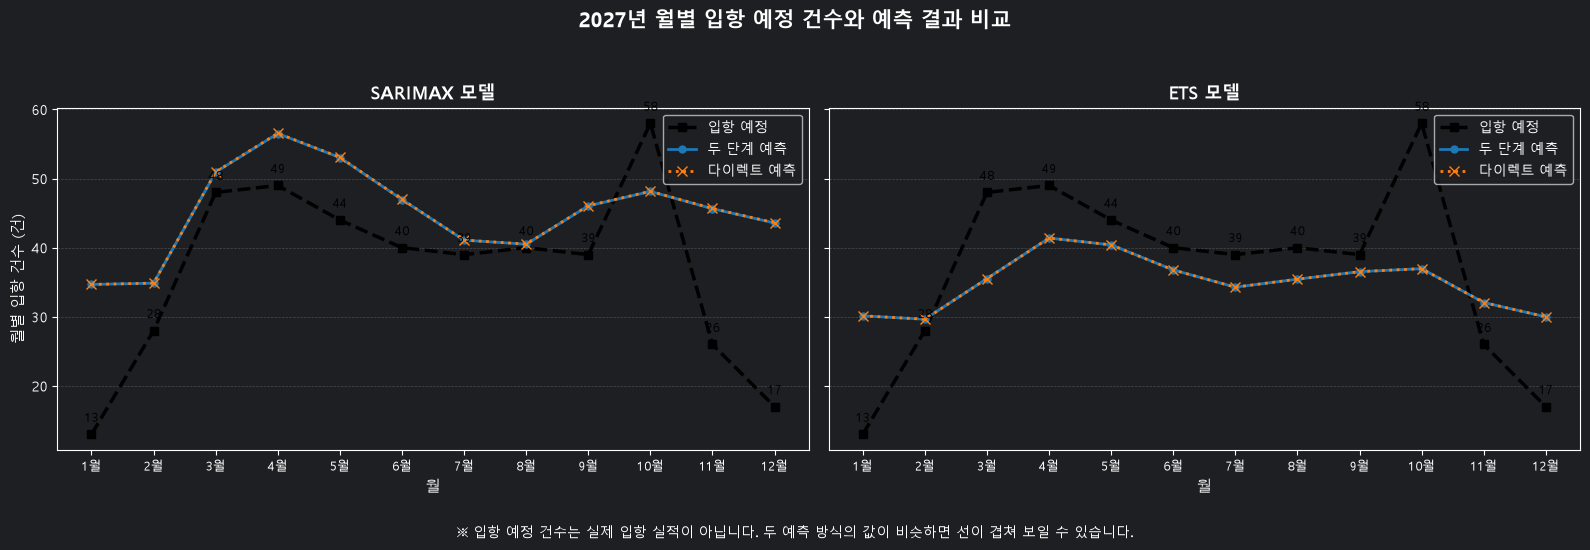


■ 2027년 운영계획 검토
입항 예정 건수가 가장 많은 월: 2027-10 (58건)
SARIMAX 두 단계: 예정 대비 편차가 가장 큰 월 2027-12 (+26.58건), 예정 초과 11개월, 예정 미달 1개월
SARIMAX 다이렉트: 예정 대비 편차가 가장 큰 월 2027-12 (+26.61건), 예정 초과 11개월, 예정 미달 1개월
ETS 두 단계: 예정 대비 편차가 가장 큰 월 2027-10 (-21.03건), 예정 초과 4개월, 예정 미달 8개월
ETS 다이렉트: 예정 대비 편차가 가장 큰 월 2027-10 (-21.03건), 예정 초과 4개월, 예정 미달 8개월

■ 분석 완료
2027년 입항 예정 건수: 441건
비교 모델: SARIMAX, ETS
예측 방식: 두 단계, 다이렉트
분석 기간: 2027년 1~12월
예정 대비 편차 = 예측 건수 - 입항 예정 건수


In [13]:
# ==================================================
# 12. 2027년 입항 예정 건수와 예측 결과 비교
#     - SARIMAX 두 단계 및 다이렉트
#     - ETS 두 단계 및 다이렉트
#     - 월별·연간 예정 대비 편차 분석
#     - 한국어 그래프 시각화
# ==================================================


# 한글 폰트 설정 (Windows)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False


# 1. 분석 가정

schedule_comparison_assumptions = pd.DataFrame({
    '구분': [
        '입항 예정 건수',
        '모델 예측값',
        '비교 목적',
        '통계적 검정'
    ],
    '내용': [
        '2027년 입항 예정 스케줄이며 실제 입항 실적이 아님',
        '2026년 9월까지의 실적을 기반으로 산출한 전망',
        '예정 건수와 예측 건수의 차이를 파악',
        '통계적 가설검정 없이 기술적 편차 분석 수행'
    ]
})

print("■ 2027년 입항 예정 건수 비교 분석 가정")
display(schedule_comparison_assumptions)


# 2. 예정 대비 편차 판정 기준

schedule_comparison_criteria = pd.DataFrame({
    '항목': [
        '예정 대비 편차 > 0',
        '예정 대비 편차 = 0',
        '예정 대비 편차 < 0',
        '예정 대비 편차율(%)'
    ],
    '해석': [
        '모델 예측 건수가 예정 건수보다 많음',
        '모델 예측 건수와 예정 건수가 같음',
        '모델 예측 건수가 예정 건수보다 적음',
        '예정 건수 대비 차이의 상대적 크기'
    ]
})

print("\n■ 예정 대비 편차 판정 기준")
display(schedule_comparison_criteria)


# 3. 2027년 월별 입항 예정 건수

schedule_2027 = pd.Series(
    [13, 28, 48, 49, 44, 40, 39, 40, 39, 58, 26, 17],
    index=year_2027_index,
    name='입항 예정 건수'
)

assert len(schedule_2027) == 12
assert schedule_2027.sum() == 441

print("\n■ 2027년 입항 예정 건수")
print(f"연간 예정 합계: {schedule_2027.sum():,.0f}건")


# 4. 2027년 월별 예정 건수와 예측값 비교

schedule_2027_comparison = pd.DataFrame({
    '연월': year_2027_index.strftime('%Y-%m'),
    '입항 예정 건수': schedule_2027.to_numpy()
})

for model_type in ['SARIMAX', 'ETS']:

    staged_forecast = forecast_results[model_type][
        'forecast_2027_staged'
    ].reindex(year_2027_index)

    direct_forecast = forecast_results[model_type][
        'forecast_2027_direct'
    ].reindex(year_2027_index)

    if staged_forecast.isna().any() or direct_forecast.isna().any():
        raise ValueError(
            f'{model_type}: 2027년 예측값 또는 날짜를 확인하세요.'
        )

    # 모델별 예측값
    schedule_2027_comparison[
        f'{model_type} 두 단계'
    ] = staged_forecast.to_numpy()

    schedule_2027_comparison[
        f'{model_type} 다이렉트'
    ] = direct_forecast.to_numpy()

    # 예정 대비 편차 = 예측값 - 예정 건수
    schedule_2027_comparison[
        f'{model_type} 두 단계 편차'
    ] = (
        staged_forecast.to_numpy()
        - schedule_2027.to_numpy()
    )

    schedule_2027_comparison[
        f'{model_type} 다이렉트 편차'
    ] = (
        direct_forecast.to_numpy()
        - schedule_2027.to_numpy()
    )

print("\n■ 2027년 월별 예정 건수와 예측값 및 편차")
display(schedule_2027_comparison.round(2))


# 5. 2027년 연간 예정 건수와 예측 결과 비교

schedule_2027_summary_rows = []

for model_type in ['SARIMAX', 'ETS']:

    for method_name, forecast_key in [
        ('두 단계', 'forecast_2027_staged'),
        ('다이렉트', 'forecast_2027_direct')
    ]:

        annual_forecast = forecast_results[
            model_type
        ][forecast_key].sum()

        annual_schedule = schedule_2027.sum()

        annual_difference = annual_forecast - annual_schedule

        annual_difference_rate = (
            annual_difference / annual_schedule * 100
        )

        schedule_2027_summary_rows.append({
            '모델': model_type,
            '예측 방식': method_name,
            '연간 예정 건수': annual_schedule,
            '연간 예측 건수': annual_forecast,
            '예정 대비 편차': annual_difference,
            '예정 대비 편차율(%)': annual_difference_rate
        })

schedule_2027_summary = pd.DataFrame(
    schedule_2027_summary_rows
)

print("\n■ 2027년 연간 예정 건수와 모델별 예측 비교")
display(schedule_2027_summary.round(2))


# 6. 월별 예정 건수와 예측 결과 그래프

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5.5),
    sharey=True
)

months = np.arange(1, 13)

for ax, model_type in zip(
    axes, ['SARIMAX', 'ETS']
):

    # 6-1. 입항 예정 건수
    ax.plot(
        months,
        schedule_2027.to_numpy(),
        color='black',
        linestyle='--',
        marker='s',
        linewidth=2.5,
        markersize=6,
        label='입항 예정'
    )

    # 6-2. 두 단계 예측
    ax.plot(
        months,
        forecast_results[model_type][
            'forecast_2027_staged'
        ].reindex(year_2027_index).to_numpy(),
        color='tab:blue',
        linestyle='-',
        marker='o',
        linewidth=2,
        markersize=5,
        label='두 단계 예측'
    )

    # 6-3. 다이렉트 예측
    ax.plot(
        months,
        forecast_results[model_type][
            'forecast_2027_direct'
        ].reindex(year_2027_index).to_numpy(),
        color='tab:orange',
        linestyle=':',
        marker='x',
        linewidth=2,
        markersize=7,
        label='다이렉트 예측'
    )

    # 6-4. 입항 예정 건수 숫자 표시
    for month, value in zip(
        months,
        schedule_2027.to_numpy()
    ):
        ax.annotate(
            f'{value:.0f}',
            (month, value),
            xytext=(0, 9),
            textcoords='offset points',
            ha='center',
            fontsize=9,
            color='black'
        )

    # 6-5. 그래프 제목 및 축
    ax.set_title(
        f'{model_type} 모델',
        fontsize=13,
        fontweight='bold'
    )

    ax.set_xlabel('월', fontsize=11)

    ax.set_xticks(months)
    ax.set_xticklabels(
        [f'{m}월' for m in months],
        fontsize=9
    )

    ax.grid(
        axis='y',
        linestyle='--',
        alpha=0.3
    )

    ax.legend(
        loc='upper right',
        fontsize=10
    )

axes[0].set_ylabel(
    '월별 입항 건수 (건)',
    fontsize=11
)

fig.suptitle(
    '2027년 월별 입항 예정 건수와 예측 결과 비교',
    fontsize=15,
    fontweight='bold'
)

# 그래프 아래 설명
fig.text(
    0.5,
    0.02,
    '※ 입항 예정 건수는 실제 입항 실적이 아닙니다. '
    '두 예측 방식의 값이 비슷하면 선이 겹쳐 보일 수 있습니다.',
    ha='center',
    fontsize=10
)

plt.tight_layout(
    rect=[0, 0.07, 1, 0.94]
)

display(fig)
plt.close(fig)


# 7. 운영계획 검토를 위한 주요 월 확인

print("\n■ 2027년 운영계획 검토")

peak_schedule_month = schedule_2027.idxmax()
peak_schedule_value = schedule_2027.max()

print(
    f"입항 예정 건수가 가장 많은 월: "
    f"{peak_schedule_month.strftime('%Y-%m')} "
    f"({peak_schedule_value:.0f}건)"
)

for model_type in ['SARIMAX', 'ETS']:

    for method_name, forecast_key in [
        ('두 단계', 'forecast_2027_staged'),
        ('다이렉트', 'forecast_2027_direct')
    ]:

        predicted = forecast_results[
            model_type
        ][forecast_key].reindex(year_2027_index)

        deviation = (
            predicted.to_numpy()
            - schedule_2027.to_numpy()
        )

        max_index = np.argmax(np.abs(deviation))
        max_month = year_2027_index[max_index]

        above_count = np.sum(deviation > 0)
        below_count = np.sum(deviation < 0)

        print(
            f"{model_type} {method_name}: "
            f"예정 대비 편차가 가장 큰 월 "
            f"{max_month.strftime('%Y-%m')} "
            f"({deviation[max_index]:+.2f}건), "
            f"예정 초과 {above_count}개월, "
            f"예정 미달 {below_count}개월"
        )


# 8. 최종 실행 결과 확인

print("\n■ 분석 완료")
print(f"2027년 입항 예정 건수: {schedule_2027.sum():.0f}건")
print("비교 모델: SARIMAX, ETS")
print("예측 방식: 두 단계, 다이렉트")
print("분석 기간: 2027년 1~12월")
print("예정 대비 편차 = 예측 건수 - 입항 예정 건수")


# 13. 최종 미래 예측 모형 및 예측 방식 선정

In [14]:

# ==================================================
# 13. 최종 미래 예측 모형 및 예측 방식 선정
# ==================================================
# 선정 과정
# 1. SARIMAX·ETS의 모형별 선정 결과 확인
# 2. 2026년 1~9월 예측 성능 비교
# 3. 2027년 두 단계·다이렉트 예측 차이 확인
# 4. 최종 ETS(A,N,A)와 다이렉트 방식 채택
# 5. 최종 2026·2027년 전망값 지정
# 6. 선정 모형의 한계 확인
# 7. 최종 결과 출력


# 1. SARIMAX·ETS 모형별 선정 결과 확인

# 1-1. 각 모형의 선정 결과
final_model_comparison = pd.DataFrame([
    {
        '모형': 'SARIMAX',
        '선정 구조': f"SARIMAX{sar_selected['model']}",
        'AICc': sar_selected['AICc'],
        'Ljung-Box p값': sar_selected['LB_p값'],
        'Ljung-Box 통과': sar_selected['LB_p값'] > 0.05,
        '선정 근거': '통계적 선정 조건 충족 후 AICc 비교'
    },
    {
        '모형': 'ETS',
        '선정 구조': chosen_ets['model'],
        'AICc': chosen_ets['AICc'],
        'Ljung-Box p값': chosen_ets['LB_p값'],
        'Ljung-Box 통과': chosen_ets['LB_p값'] > 0.05,
        '선정 근거': selection_rule_ets
    }
])

print("■ 1. SARIMAX·ETS 모형별 선정 결과")
display(final_model_comparison.round(3))

print(
    "※ AICc는 각 모형 계열 내부의 후보 선정에 사용했으며, "
    "서로 다른 모형 계열 간 최종 선택 근거로 직접 비교하지 않습니다."
)


# 1-2. ETS 후보 6개 중 Ljung-Box 통과 모형 확인
ets_lb_pass = ets_table[
    (ets_table['LB_p값'] > 0.05) &
    (np.isfinite(ets_table['AICc']))
]

print("\n■ ETS 후보 모형의 잔차 검정 확인")
print(f"전체 ETS 후보: {len(ets_table)}개")
print(f"Ljung-Box 통과 후보: {len(ets_lb_pass)}개")
print(f"최종 ETS 선정 방식: {selection_rule_ets}")

if ets_lb_pass.empty:
    print(
        "※ Ljung-Box 검정을 통과한 ETS 후보가 없어 "
        "AICc가 가장 낮은 모형을 잠정 선정했습니다."
    )


# 2. 2026년 1~9월 예측 성능 비교

# 2-1. 검증기간의 다섯 가지 예측오차 지표 사용
metric_info = {
    'MAE': ('건', '월평균 절대오차'),
    'RMSE': ('건', '큰 오차에 더 민감한 지표'),
    'RMSSE': ('', '계절 변동을 기준으로 보정한 오차'),
    'MAPE(%)': ('%p', '월별 평균 절대오차율'),
    'WAPE(%)': ('%p', '전체 입항건수 대비 절대오차율')
}

validation_indexed = validation_metrics.set_index('모델')

comparison_rows = []

for metric, (unit, meaning) in metric_info.items():

    sar_value = float(
        validation_indexed.loc['SARIMAX', metric]
    )

    ets_value = float(
        validation_indexed.loc['ETS', metric]
    )

    improvement = sar_value - ets_value

    if unit == '건':
        difference_text = f'{improvement:.2f}건 감소'
    elif unit == '%p':
        difference_text = f'{improvement:.2f}%p 감소'
    else:
        difference_text = f'{improvement:.2f} 감소'

    comparison_rows.append({
        '평가 지표': metric,
        '의미': meaning,
        'SARIMAX': sar_value,
        'ETS': ets_value,
        'ETS 개선 폭': difference_text,
        '우수 모형': (
            'ETS' if ets_value < sar_value
            else 'SARIMAX' if sar_value < ets_value
            else '동일'
        )
    })

final_validation_comparison = pd.DataFrame(
    comparison_rows
)

print("\n■ 2. 2026년 1~9월 검증기간 예측 성능")
display(final_validation_comparison.round(2))


# 2-2. 주요 지표 개선 정도 계산
sar_mae = float(
    validation_indexed.loc['SARIMAX', 'MAE']
)

ets_mae = float(
    validation_indexed.loc['ETS', 'MAE']
)

sar_wape = float(
    validation_indexed.loc['SARIMAX', 'WAPE(%)']
)

ets_wape = float(
    validation_indexed.loc['ETS', 'WAPE(%)']
)

mae_reduction = sar_mae - ets_mae

mae_reduction_rate = (
    mae_reduction / sar_mae * 100
)

wape_reduction = sar_wape - ets_wape


# 2-3. 모든 지표에서 ETS가 우수한지 검증
ets_better_all = all(
    validation_indexed.loc['ETS', metric]
    < validation_indexed.loc['SARIMAX', metric]
    for metric in metric_info
)

print("\n■ 검증기간 주요 성능 차이")

print(
    f"MAE: {sar_mae:.2f}건 → {ets_mae:.2f}건 "
    f"({mae_reduction:.2f}건 감소)"
)

print(
    f"MAE 상대 감소율: {mae_reduction_rate:.2f}%"
)

print(
    f"WAPE: {sar_wape:.2f}% → {ets_wape:.2f}% "
    f"({wape_reduction:.2f}%p 감소)"
)

print(f"다섯 가지 지표 모두 ETS 우수: {ets_better_all}")


# 3. 2027년 예측 방식 비교

# 3-1. 두 단계·다이렉트 예측값 불러오기
ets_staged = forecast_results['ETS'][
    'forecast_2027_staged'
]

ets_direct = forecast_results['ETS'][
    'forecast_2027_direct'
]

# 3-2. 월별 예측 차이 계산
method_difference = (
    ets_staged.to_numpy(dtype=float)
    - ets_direct.to_numpy(dtype=float)
)

# 3-3. 비교 결과표
final_method_comparison = pd.DataFrame([{
    '모형': chosen_ets['model'],
    '두 단계 연간 전망': float(ets_staged.sum()),
    '다이렉트 연간 전망': float(ets_direct.sum()),
    '연간 합계 차이': float(
        ets_staged.sum() - ets_direct.sum()
    ),
    '월평균 절대차이': float(
        np.mean(np.abs(method_difference))
    ),
    '월최대 절대차이': float(
        np.max(np.abs(method_difference))
    )
}])

print("\n■ 3. ETS의 2027년 예측 방식별 결과 비교")
display(final_method_comparison.round(3))

print(
    "※ 두 방식의 예측값 차이는 정확도 차이가 아닙니다."
)

print(
    "※ 실제 관측값을 이용해 두 방식의 정확도를 "
    "직접 비교한 결과는 아닙니다."
)


# 4. 최종 미래 예측 모형 및 방식 선정

# 4-1. 최종 선정 조건 확인
final_model = chosen_ets['model']
final_method = '다이렉트 예측'

assert final_model == 'ETS(A,N,A)', (
    f'ETS 최종 모형 확인 필요: {final_model}'
)

assert ets_better_all, (
    '검증기간에서 ETS가 모든 지표에서 우수하지 않습니다. '
    '최종 모형 선정 근거를 재검토해야 합니다.'
)


# 4-2. 최종 선정 근거표
final_selection_table = pd.DataFrame({
    '선정 단계': [
        '① ETS 내부 모형 선정',
        '② 잔차 검정 확인',
        '③ 검증기간 MAE 비교',
        '④ 검증기간 WAPE 비교',
        '⑤ 기타 예측오차 지표',
        '⑥ 예측 방식 비교',
        '⑦ 최종 적용 방식',
        '⑧ 최종 모형'
    ],
    '판단 근거': [
        (
            f'ETS 후보 6개 중 AICc 최소 '
            f'({chosen_ets["AICc"]:.3f})'
        ),
        (
            f'Ljung-Box p={chosen_ets["LB_p값"]:.3f} '
            f'/ 통과 여부: '
            f'{bool(chosen_ets["LB_p값"] > 0.05)}'
        ),
        (
            f'SARIMAX {sar_mae:.2f}건 → '
            f'ETS {ets_mae:.2f}건 '
            f'({mae_reduction:.2f}건 감소)'
        ),
        (
            f'SARIMAX {sar_wape:.2f}% → '
            f'ETS {ets_wape:.2f}% '
            f'({wape_reduction:.2f}%p 감소)'
        ),
        (
            f'RMSE·RMSSE·MAPE까지 포함한 '
            f'전체 지표 ETS 우수: {ets_better_all}'
        ),
        (
            f'2027년 두 방식의 월평균 절대차이 '
            f'{np.mean(np.abs(method_difference)):.3f}건'
        ),
        '예측값을 학습자료에 재투입하지 않는 다이렉트 방식',
        final_model
    ],
    '판단': [
        'AICc 최소 모형 선정',
        (
            '잔차 검정 통과'
            if chosen_ets['LB_p값'] > 0.05
            else '잔차 검정 미통과 - 분석 한계'
        ),
        'ETS 우수',
        'ETS 우수',
        'ETS 우수',
        '두 방식의 점예측 유사',
        '자료 활용 방식에 따른 선택',
        '최종 활용 모형 확정'
    ]
})

print("\n■ 4. 최종 미래 예측 모형 및 방식 선정 근거")
display(final_selection_table)


# 5. 최종 미래 입항건수 예측값 지정

# 5-1. 2026년 4분기 ETS 예측값
final_forecast_2026_q4 = forecast_results['ETS'][
    'forecast_2026_q4'
].copy()

# 5-2. 2027년 ETS 다이렉트 예측값
final_forecast_2027 = forecast_results['ETS'][
    'forecast_2027_direct'
].copy()


# 5-3. 2026년 연간 전망
# 1~9월 실제 입항건수 + 4분기 예측 입항건수
final_forecast_2026_total = (
    float(valid.sum())
    + float(final_forecast_2026_q4.sum())
)

# 5-4. 2027년 연간 전망
final_forecast_2027_total = float(
    final_forecast_2027.sum()
)

final_annual_forecast_table = pd.DataFrame({
    '연도': [2026, 2027],
    '최종 모형': [final_model, final_model],
    '예측 방식': [
        '1~9월 실제값 + 4분기 ETS 예측',
        'ETS 다이렉트 예측'
    ],
    '연간 입항건수 전망': [
        final_forecast_2026_total,
        final_forecast_2027_total
    ]
})

print("\n■ 5. 최종 연간 입항건수 전망")
display(final_annual_forecast_table.round(2))


# 6. 최종 모형 적용 시 유의사항

final_limitations = pd.DataFrame({
    '검토 항목': [
        'ETS 잔차 검정',
        '검증기간 예측오차',
        '검증기간 범위',
        '다이렉트 방식 선정'
    ],
    '확인 사항': [
        (
            f'Ljung-Box p={chosen_ets["LB_p값"]:.3f} '
            f'(0.05 이하: 잔차 자기상관 가능성)'
        ),
        (
            f'ETS WAPE {ets_wape:.2f}% '
            f'(예측오차가 여전히 존재)'
        ),
        '2026년 1~9월, 총 9개월 기준',
        (
            '두 단계 방식보다 정확하다고 검증된 것은 아님'
        )
    ]
})

print("\n■ 6. 최종 모형의 분석 한계")
display(final_limitations)


# 7. 최종 선정 결과

print("\n■ 최종 미래 예측 모형 선정 완료")

print(f"최종 모형: {final_model}")
print(f"최종 예측 방식: {final_method}")

print(
    f"선정 근거: 검증기간 MAE "
    f"{mae_reduction:.2f}건 감소, "
    f"WAPE {wape_reduction:.2f}%p 감소"
)

print(
    "예측 방식 선정 근거: 예측값을 학습자료에 "
    "재투입하지 않고 연속 예측"
)

print(
    f"2026년 연간 전망: "
    f"{final_forecast_2026_total:.2f}건"
)

print(
    f"2027년 연간 전망: "
    f"{final_forecast_2027_total:.2f}건"
)


■ 1. SARIMAX·ETS 모형별 선정 결과


,모형,선정 구조,AICc,Ljung-Box p값,Ljung-Box 통과,선정 근거
0,SARIMAX,"SARIMAX(1, 1, 2)x(0, 1, 1, 12)",773.747,0.451,True,통계적 선정 조건 충족 후 AICc 비교
1,ETS,"ETS(A,N,A)",944.325,0.002,False,"Ljung-Box 미통과, AICc 최소"


※ AICc는 각 모형 계열 내부의 후보 선정에 사용했으며, 서로 다른 모형 계열 간 최종 선택 근거로 직접 비교하지 않습니다.

■ ETS 후보 모형의 잔차 검정 확인
전체 ETS 후보: 6개
Ljung-Box 통과 후보: 0개
최종 ETS 선정 방식: Ljung-Box 미통과, AICc 최소
※ Ljung-Box 검정을 통과한 ETS 후보가 없어 AICc가 가장 낮은 모형을 잠정 선정했습니다.

■ 2. 2026년 1~9월 검증기간 예측 성능


,평가 지표,의미,SARIMAX,ETS,ETS 개선 폭,우수 모형
0,MAE,월평균 절대오차,18.48,15.07,3.41건 감소,ETS
1,RMSE,큰 오차에 더 민감한 지표,20.04,17.42,2.62건 감소,ETS
2,RMSSE,계절 변동을 기준으로 보정한 오차,2.42,2.10,0.32 감소,ETS
3,MAPE(%),월별 평균 절대오차율,50.41,38.42,11.99%p 감소,ETS
4,WAPE(%),전체 입항건수 대비 절대오차율,52.14,42.52,9.62%p 감소,ETS



■ 검증기간 주요 성능 차이
MAE: 18.48건 → 15.07건 (3.41건 감소)
MAE 상대 감소율: 18.45%
WAPE: 52.14% → 42.52% (9.62%p 감소)
다섯 가지 지표 모두 ETS 우수: True

■ 3. ETS의 2027년 예측 방식별 결과 비교


,모형,두 단계 연간 전망,다이렉트 연간 전망,연간 합계 차이,월평균 절대차이,월최대 절대차이
0,"ETS(A,N,A)",419.22,419.211,0.008,0.001,0.002


... (3 outputs left out)

,연도,최종 모형,예측 방식,연간 입항건수 전망
0,2026,"ETS(A,N,A)",1~9월 실제값 + 4분기 ETS 예측,418.04
1,2027,"ETS(A,N,A)",ETS 다이렉트 예측,419.21



■ 6. 최종 모형의 분석 한계


,검토 항목,확인 사항
0,ETS 잔차 검정,Ljung-Box p=0.002 (0.05 이하: 잔차 자기상관 가능성)
1,검증기간 예측오차,ETS WAPE 42.52% (예측오차가 여전히 존재)
2,검증기간 범위,"2026년 1~9월, 총 9개월 기준"
3,다이렉트 방식 선정,두 단계 방식보다 정확하다고 검증된 것은 아님



■ 최종 미래 예측 모형 선정 완료
최종 모형: ETS(A,N,A)
최종 예측 방식: 다이렉트 예측
선정 근거: 검증기간 MAE 3.41건 감소, WAPE 9.62%p 감소
예측 방식 선정 근거: 예측값을 학습자료에 재투입하지 않고 연속 예측
2026년 연간 전망: 418.04건
2027년 연간 전망: 419.21건


# 14. 대시보드용 ETS 다이렉트 예측 결과 정리

In [15]:
# ==================================================
# 14. 대시보드용 ETS 다이렉트 예측 결과 정리
# ==================================================
# ETS 모델의 다이렉트 예측을 기준으로 예정 스케줄의 입항수와 모델이 예측한 입항수의 차이와 절대 차이율(%)


# 1. 2027년 ETS 다이렉트 예측값 추출

ets_direct_forecast = forecast_results['ETS'][
    'forecast_2027_direct'
].reindex(year_2027_index)

# 예정 스케줄
scheduled_arrivals = schedule_2027.reindex(year_2027_index)

# 날짜 및 데이터 확인
if ets_direct_forecast.isna().any() or scheduled_arrivals.isna().any():
    raise ValueError("2027년 ETS 예측값 또는 입항 예정 건수를 확인하세요.")


# 2. 월별 예정 입항수와 예측 입항수 비교

ets_dashboard = pd.DataFrame({
    '연월': year_2027_index.strftime('%Y-%m'),
    '입항 예정 건수': scheduled_arrivals.to_numpy(),
    'ETS 다이렉트 예측 입항수': ets_direct_forecast.to_numpy()
})

# 예측값 - 예정 건수
ets_dashboard['예정 대비 차이'] = (
    ets_dashboard['ETS 다이렉트 예측 입항수']
    - ets_dashboard['입항 예정 건수']
)

# 절대차이
ets_dashboard['절대차이'] = (
    ets_dashboard['예정 대비 차이'].abs()
)

# 절대차이율(%)
ets_dashboard['절대차이율(%)'] = np.where(
    ets_dashboard['입항 예정 건수'] != 0,
    ets_dashboard['절대차이']
    / ets_dashboard['입항 예정 건수'] * 100,
    np.nan
)


# 3. 월별 비교 결과 출력

print("\n■ 2027년 ETS 다이렉트 예측 대비 입항 예정 스케줄 비교")

display(
    ets_dashboard.round(2)
)


# 4. 연간 입항 예정 건수와 ETS 예측 결과 비교

annual_schedule = scheduled_arrivals.sum()
annual_forecast = ets_direct_forecast.sum()

annual_difference = annual_forecast - annual_schedule
annual_absolute_difference = abs(annual_difference)

annual_absolute_difference_rate = (
    annual_absolute_difference / annual_schedule * 100
    if annual_schedule != 0 else np.nan
)

ets_annual_dashboard = pd.DataFrame({
    '구분': ['2027년 연간'],
    '입항 예정 건수': [annual_schedule],
    'ETS 다이렉트 예측 입항수': [annual_forecast],
    '예정 대비 차이': [annual_difference],
    '절대차이': [annual_absolute_difference],
    '절대차이율(%)': [annual_absolute_difference_rate]
})

print("\n■ 2027년 ETS 다이렉트 연간 비교 결과")

display(
    ets_annual_dashboard.round(2)
)


# 5. 대시보드용 핵심 결과 출력

print("\n■ ETS 다이렉트 예측 핵심 지표")

print(f"① 2027년 입항 예정 건수: {annual_schedule:,.0f}건")
print(f"② ETS 다이렉트 예측 입항수: {annual_forecast:,.2f}건")
print(f"③ 예정 대비 차이: {annual_difference:+,.2f}건")
print(f"④ 절대차이: {annual_absolute_difference:,.2f}건")
print(f"⑤ 절대차이율: {annual_absolute_difference_rate:.2f}%")



■ 2027년 ETS 다이렉트 예측 대비 입항 예정 스케줄 비교


,연월,입항 예정 건수,ETS 다이렉트 예측 입항수,예정 대비 차이,절대차이,절대차이율(%)
0,2027-01,13,30.14,17.14,17.14,131.85
1,2027-02,28,29.66,1.66,1.66,5.91
2,2027-03,48,35.52,-12.48,12.48,25.99
3,2027-04,49,41.40,-7.60,7.60,15.52
4,2027-05,44,40.41,-3.59,3.59,8.16
5,2027-06,40,36.78,-3.22,3.22,8.05
6,2027-07,39,34.29,-4.71,4.71,12.08
7,2027-08,40,35.45,-4.55,4.55,11.38
8,2027-09,39,36.53,-2.47,2.47,6.33
9,2027-10,58,36.97,-21.03,21.03,36.25



■ 2027년 ETS 다이렉트 연간 비교 결과


,구분,입항 예정 건수,ETS 다이렉트 예측 입항수,예정 대비 차이,절대차이,절대차이율(%)
0,2027년 연간,441,419.21,-21.79,21.79,4.94



■ ETS 다이렉트 예측 핵심 지표
① 2027년 입항 예정 건수: 441건
② ETS 다이렉트 예측 입항수: 419.21건
③ 예정 대비 차이: -21.79건
④ 절대차이: 21.79건
⑤ 절대차이율: 4.94%
